# Ejercicios UD1 · Bloque 2 — Análisis exploratorio de datos (AED)

**Módulo:** Depuración, Limpieza y Clasificación de Datos (5109)
**Unidad Didáctica:** UD1 — Análisis exploratorio de datos: estructura, variables y calidad
**Alumno/a: Alejandro Suárez Durán**
**Fecha de entrega:**

---

Este cuaderno recoge los ejercicios del **Bloque 2** de la UD1. Están organizados por sesiones, igual que los cuadernos de teoría:

| Sesión | Cuaderno de teoría | Ejercicios |
|---|---|---|
| 1 | `B2_S1_Concepto_e_Inspeccion_Inicial` | 1.1 – 1.4 |
| 2 | `B2_S2_Variables_y_Relaciones` | 2.1 – 2.5 |
| 3 | `B2_S3_Visualizacion_y_Perfilado` | 3.1 – 3.4 |

**Todos los ejercicios trabajan sobre el mismo conjunto de datos**: pacientes estudiados por sospecha de **enfermedad cardiaca**. Así, al terminar el cuaderno habrás hecho un AED completo de principio a fin, que resumirás en una ficha de síntesis (ejercicio 3.4).

Los ejercicios se encadenan: el DataFrame `heart` que preparas en la Sesión 1 se usa en el resto del cuaderno. Algunos ejercicios son preguntas de reflexión (responde en la celda de texto) y otros son de código (escribe tu solución donde pone `TODO`).

> **Antes de empezar:** copia este cuaderno a tu carpeta `mis_cuadernos/` y trabaja sobre la copia, así `git pull` no te dará conflictos.
>
> **Cómo entregar:** reinicia el kernel y ejecuta todas las celdas (**Restart** → **Run All**), comprueba que no hay errores, guarda y sube el fichero `.ipynb` al aula virtual. No hace falta que subas los informes HTML ni las imágenes que se generan.

## Criterios de evaluación

Esta relación de ejercicios evalúa los siguientes criterios de evaluación del módulo (Real Decreto 183/2026, redacción literal):

> **RA1.** Identifica la estructura y variables en los datos en el dominio de aplicación, así como su cobertura y calidad del conjunto, aplicando técnicas exploratorias mediante análisis exploratorios de datos (AED) para la selección de atributos clave en el entrenamiento posterior.

| CE | Criterio de evaluación | Ejercicios |
|:--:|------------------------|:----------:|
| **1.b** | Se han detectado datos incorrectamente introducidos, ausencia de valores, una mala codificación de las variables o valores atípicos. | 1.2, 1.3, 1.4, 2.1, 2.4, 3.3 |
| **1.c** | Se han identificado la estructura, variables y relaciones de los conjuntos de datos aplicando técnicas exploratorias. | Todos |
| **1.d** | Se han identificado entidades, volumetrías, relaciones y atributos, para documentar cada conjunto de datos, describiendo sus características. | 1.1, 1.2, 1.4, 3.4 |

In [1]:
# Librerías que se usan en todo el cuaderno
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

print('✅ Librerías cargadas')

✅ Librerías cargadas


## El conjunto de datos: Heart Failure Prediction

Las enfermedades cardiovasculares son la primera causa de muerte en el mundo. Detectarlas pronto, a partir de pruebas sencillas, es uno de los usos clásicos del aprendizaje automático en medicina.

El dataset **[Heart Failure Prediction](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction)** (Kaggle, fedesoriano, 2021) se construyó **juntando cinco conjuntos de datos** del repositorio UCI, recogidos en hospitales distintos: Cleveland, Hungría, Suiza, Long Beach (VA) y Statlog. Entre todos sumaban 1.190 registros; el autor eliminó los duplicados y dejó **918 pacientes**.

Cada fila es un paciente al que se estudió por sospecha de enfermedad cardiaca. Además de datos básicos (edad, sexo, presión, colesterol, glucosa…) se le hizo un **electrocardiograma en reposo** y una **prueba de esfuerzo** (caminar o correr en una cinta mientras se registra el corazón).

| Variable | Descripción | Valores / unidades |
|---|---|---|
| `Age` | Edad del paciente | años |
| `Sex` | Sexo | `M` hombre · `F` mujer |
| `ChestPainType` | Tipo de dolor torácico | `TA` angina típica · `ATA` angina atípica · `NAP` dolor no anginoso · `ASY` asintomático |
| `RestingBP` | Presión arterial en reposo | mm Hg |
| `Cholesterol` | Colesterol en sangre | mg/dL |
| `FastingBS` | Glucosa en ayunas alta | `1` si > 120 mg/dL · `0` en otro caso |
| `RestingECG` | Electrocardiograma en reposo | `Normal` · `ST` alteración de la onda ST-T · `LVH` hipertrofia ventricular izquierda |
| `MaxHR` | Frecuencia cardiaca máxima alcanzada en la prueba de esfuerzo | pulsaciones por minuto |
| `ExerciseAngina` | Dolor de pecho (angina) provocado por el esfuerzo | `Y` sí · `N` no |
| `Oldpeak` | Desplazamiento del segmento ST durante el esfuerzo respecto al reposo | mm |
| `ST_Slope` | Pendiente del segmento ST en el pico del esfuerzo | `Up` ascendente · `Flat` plana · `Down` descendente |
| `HeartDisease` | **Variable objetivo**: diagnóstico de enfermedad cardiaca | `1` enfermo · `0` sano |

La celda siguiente descarga el fichero (solo la primera vez) a la carpeta `datos/` y lo carga. Si la descarga falla, descarga `heart.csv` desde Kaggle y guárdalo tú en `datos/heart.csv`.

> `heart_raw` es la copia **original** y no se toca en todo el cuaderno. Trabaja siempre sobre `heart`.

In [2]:
URL_HEART = 'https://raw.githubusercontent.com/imteekay/heart-failure-prediction/main/heart.csv'
ruta_heart = Path('datos') / 'heart.csv'

if not ruta_heart.exists():
    print('Descargando heart.csv...')
    ruta_heart.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve(URL_HEART, ruta_heart)

heart_raw = pd.read_csv(ruta_heart)   # copia original: no la modifiques
heart = heart_raw.copy()              # copia de trabajo
print('✅ Dataset cargado')

✅ Dataset cargado


---
# Sesión 1 — Concepto del AED e inspección inicial

## Ejercicio 1.1 — Primer contacto con los datos

**Parte A — Vistazo.**
Muestra, cada cosa en su celda o con `display()`:

1. Las dimensiones del dataset y los nombres de las columnas.
2. Las 5 primeras y las 5 últimas filas.
3. 8 filas elegidas al azar, con `random_state=42` para que el resultado sea reproducible.
4. El resumen de `info()`.
5. El número de filas duplicadas.

In [3]:
# TODO: dimensiones y columnas
print('Dimensiones del dataset:', heart.shape)
print('Columnas del dataset:', heart.columns)
print()
# TODO: primeras y últimas filas
print('Primeras 5 filas:')
print(heart.head())
print('Últimas 5 filas:')
print(heart.tail())
print()
# TODO: 8 filas al azar (random_state=42)
print('8 filas al azar:')
print(heart.sample(n=8, random_state=42))
print()
# TODO: info()
print('Información del dataset:')
heart.info()
print()
# TODO: filas duplicadas
duplicadas = heart.duplicated().sum()
print('Número de filas duplicadas:', duplicadas)

Dimensiones del dataset: (918, 12)
Columnas del dataset: Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='object')

Primeras 5 filas:
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat   

**Preguntas:**

1. ¿Qué **entidad** representa cada fila? ¿Hay alguna columna que identifique al paciente?
2. El dataset junta cinco hospitales. Sin un identificador, ¿podrías saber si el mismo paciente aparece dos veces? ¿Qué te dice el resultado de `duplicated()` y qué **no** te dice?
3. Según `info()`, ¿cuántos valores ausentes hay? ¿Te fías de esa respuesta? (Lo comprobarás en el ejercicio 1.3.)
4. Las filas están ordenadas por hospital de origen, uno detrás de otro. ¿Por qué es arriesgado sacar conclusiones mirando solo `head()`?

*Escribe aquí tus respuestas:*

1. La entidad a la que representa cada fila es al paciente. No hay una columna que identifique expresamente al paciente
2. Podría identificarse si dos filas tienen exactamente los mismos datos, ya que eso en la vida real es extremadamente dificil.
*duplicated()* nos dice si hay una o mas filas duplicadas dentro de un mismo dataset con un true/false. No nos dice que variables toma en cuenta para determinar esa duplicación.
3. Segun *info()* no hay ningun valor ausente ni nulo. No me termino de fiar, ya que no sabemos si los datos son todos validos en el sentido del formato. No sabemos como están puestos
4. Porque no sabemos bien cuales son los datos en otros hospitales, ya que con *head()* solo vemos los datos de uno

## Ejercicio 1.2 — Ficha de variables y tipos correctos

**Parte A — Diagnóstico.**
Construye un DataFrame `ficha` con **una fila por columna** del dataset y estas columnas:

| variable | dtype | n_unicos | ejemplos | tipo_estadistico |
|---|---|---|---|---|

- `ejemplos`: los 4 primeros valores distintos de la columna.
- `tipo_estadistico`: escríbelo tú con un diccionario. Usa una de estas etiquetas: *numérica continua*, *numérica discreta*, *categórica nominal*, *categórica ordinal* o *binaria*.

In [4]:
# TODO: ficha de variables
tipo_estadistico = {
    'Age': 'numérica discreta',
    'Sex': 'binaria',
    'ChestPainType': 'categórica nominal',
    'RestingBP': 'numérica continua',
    'Cholesterol': 'numérica continua',
    'FastingBS': 'binaria',
    'RestingECG': 'categórica nominal',
    'MaxHR': 'numérica continua',
    'ExerciseAngina': 'binaria',
    'Oldpeak': 'numérica continua',
    'ST_Slope': 'categórica ordinal',
    'HeartDisease': 'binaria'
}

ficha = pd.DataFrame({
    'variable': heart.columns,
    'dtype': heart.dtypes.values,
    'n_unicos': heart.nunique().values,
    'ejemplos': [heart[col].drop_duplicates().head(4).tolist() for col in heart.columns],
    'tipo_estadistico': [tipo_estadistico[col] for col in heart.columns]
})
ficha

,variable,dtype,n_unicos,ejemplos,tipo_estadistico
0,Age,int64,50,"[40, 49, 37, 48]",numérica discreta
1,Sex,object,2,"[M, F]",binaria
2,ChestPainType,object,4,"[ATA, NAP, ASY, TA]",categórica nominal
3,RestingBP,int64,67,"[140, 160, 130, 138]",numérica continua
4,Cholesterol,int64,222,"[289, 180, 283, 214]",numérica continua
5,FastingBS,int64,2,"[0, 1]",binaria
6,RestingECG,object,3,"[Normal, ST, LVH]",categórica nominal
7,MaxHR,int64,119,"[172, 156, 98, 108]",numérica continua
8,ExerciseAngina,object,2,"[N, Y]",binaria
9,Oldpeak,float64,53,"[0.0, 1.0, 1.5, 2.0]",numérica continua


**Parte B — Corrección de tipos.**

1. Calcula la memoria que ocupa `heart` (`heart.memory_usage(deep=True).sum()`).
2. Convierte a `category` las columnas de texto: `Sex`, `ChestPainType`, `RestingECG`, `ExerciseAngina`.
3. Decide si `ST_Slope` es ordinal. Si lo es, conviértela con un `pd.CategoricalDtype(..., ordered=True)` en el orden que consideres correcto.
4. Decide qué hacer con `FastingBS` y `HeartDisease`: ¿las dejas como enteros o las conviertes? Justifícalo en las preguntas.
5. Vuelve a calcular la memoria y muestra `heart.dtypes`.

In [5]:
# TODO: memoria antes
memoria_antes = heart.memory_usage(deep=True).sum()
print(f'Memoria antes: {memoria_antes:,} bytes')

# TODO: conversión de tipos
# Las columnas de texto pasan a category
columnas = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina']
heart[columnas] = heart[columnas].astype('category')

# ST_Slope es ordinal: Down < Flat < Up
heart['ST_Slope'] = heart['ST_Slope'].astype(pd.CategoricalDtype(['Down', 'Flat', 'Up'], ordered=True))

# FastingBS y HeartDisease solo valen 0 o 1, así que pasan a bool
columnas2 = ['FastingBS', 'HeartDisease']
heart[columnas2] = heart[columnas2].astype('bool')

# TODO: memoria después y dtypes
memoria_despues = heart.memory_usage(deep=True).sum()
print(f'Memoria después: {memoria_despues:,} bytes')
print(f'Ahorro: {memoria_antes - memoria_despues:,} bytes ({(1 - memoria_despues / memoria_antes) * 100:.1f} %)')
print()
print(heart.dtypes)

Memoria antes: 288,108 bytes
Memoria después: 44,604 bytes
Ahorro: 243,504 bytes (84.5 %)

Age                  int64
Sex               category
ChestPainType     category
RestingBP            int64
Cholesterol          int64
FastingBS             bool
RestingECG        category
MaxHR                int64
ExerciseAngina    category
Oldpeak            float64
ST_Slope          category
HeartDisease          bool
dtype: object


**Preguntas:**

1. pandas ha cargado `FastingBS` como `int64`. ¿Es una variable numérica? ¿Qué significa en este caso calcular su **media**?
2. ¿Es ordinal `ST_Slope`? ¿Y `ChestPainType`? Justifica las dos respuestas.
3. ¿Cuánta memoria has ahorrado? ¿Por qué ocupa menos una columna `category` que una de texto?
4. ¿Qué decisión has tomado con `FastingBS` y `HeartDisease`? ¿Por qué?

*Escribe aquí tus respuestas:*

1. No, es una variable categórica binaria, solo vale 0 o 1. Calcular su media es calcular la proporción de pacientes que tienen la glucosa alta, que en este caso es un 23,3% de los pacientes
2. ST_Slope si es ordinal, porque Down, Flat y Up tienen un orden (descendente, plana y ascendente). ChestPainType no, es nominal, porque TA, ATA, NAP y ASY son tipos de dolor distintos y no hay un orden claro entre ellos.
3. He ahorrado 243.504 bytes, un 84,5% (de 288.108 a 44.604). Ocupa menos porque category guarda cada texto distinto una sola vez y en cada fila solo guarda un número que apunta a él, en vez de repetir el texto en las 918 filas.
4. Las he pasado a bool porque solo tienen dos valores posibles, y así ocupan menos y no se pueden usar por error como si fueran números normales.

## Ejercicio 1.3 — Estadísticos descriptivos: ¿dónde está el error?

**Parte A — Resumen estadístico.**
Muestra `describe()` de las variables numéricas (traspuesto y redondeado a 2 decimales) y `describe()` de las variables categóricas.

In [6]:
# TODO: describe() numéricas
columnas_numericas = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
print('--- Estadísticos de variables numéricas ---')
display(heart[columnas_numericas].describe().T.round(2))
print()

# TODO: describe() categóricas
columnas_categoricas = ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope', 'HeartDisease']
print('--- Estadísticos de variables categóricas ---')
display(heart[columnas_categoricas].describe())

--- Estadísticos de variables numéricas ---


,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.51,9.43,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.40,18.51,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.80,109.38,0.0,173.25,223.0,267.0,603.0
MaxHR,918.0,136.81,25.46,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.89,1.07,-2.6,0.00,0.6,1.5,6.2



--- Estadísticos de variables categóricas ---


,Sex,ChestPainType,FastingBS,RestingECG,ExerciseAngina,ST_Slope,HeartDisease
count,918,918,918,918,918,918,918
unique,2,4,2,3,2,3,2
top,M,ASY,False,Normal,N,Flat,True
freq,725,496,704,552,547,460,508


**Parte B — Valores imposibles.**

1. Cuenta cuántos **ceros** hay en cada variable numérica.
2. Cuenta cuántos valores **negativos** hay en `Oldpeak`.
3. Muestra la fila o filas con `RestingBP == 0`.
4. Dibuja un diagrama de dispersión de `Cholesterol` frente al **número de fila** (`heart.index`). Pon título y etiquetas a los ejes.

Cantidad de ceros por variable numérica:
Age              0
RestingBP        1
Cholesterol    172
MaxHR            0
Oldpeak        368
dtype: int64

Cantidad de negativos en Oldpeak: 13

Filas con RestingBP == 0:


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
449,55,M,NAP,0,0,False,Normal,155,N,1.5,Flat,True


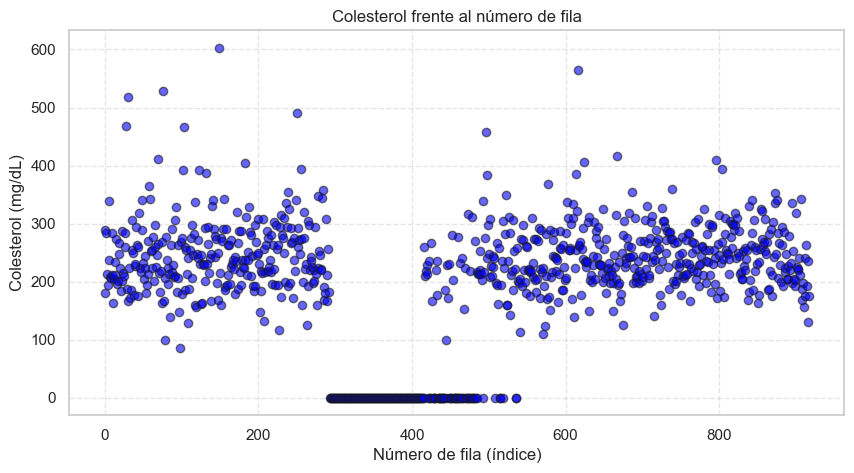

In [7]:
# TODO: ceros por variable
num_ceros = (heart[columnas_numericas] == 0).sum()
print('Cantidad de ceros por variable numérica:')
print(num_ceros)
print()

# TODO: negativos en Oldpeak
neg_oldpeak = (heart['Oldpeak'] < 0).sum()
print('Cantidad de negativos en Oldpeak:', neg_oldpeak)
print()

# TODO: filas con RestingBP == 0
print('Filas con RestingBP == 0:')
display(heart[heart['RestingBP'] == 0])

# TODO: Cholesterol frente al número de fila
plt.figure(figsize=(10, 5))
plt.scatter(heart.index, heart['Cholesterol'], alpha=0.6, color='blue', edgecolor='k')
plt.title('Colesterol frente al número de fila')
plt.xlabel('Número de fila (índice)')
plt.ylabel('Colesterol (mg/dL)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Preguntas:**

1. ¿Es posible tener un colesterol de 0 mg/dL o una presión arterial de 0 mm Hg en un paciente vivo? ¿Qué son en realidad esos ceros? ¿Por qué `info()` no los detectó?
2. ¿Qué observas en el gráfico de `Cholesterol` frente al número de fila? ¿Qué te sugiere sobre el **origen** de esos ceros?
3. `Oldpeak` tiene valores negativos. Busca qué mide esta variable y si un valor negativo tiene sentido clínico (pista: *depresión* frente a *elevación* del segmento ST). ¿Lo tratarías como un error?
4. `FastingBS` tiene muchísimos ceros. ¿Son también sospechosos? ¿Por qué?

*Escribe aquí tus respuestas:*

1. No, es imposible que un paciente vivo tenga esos numeros. Seguramente son valores que un hospital no apuntó y se quedaron en 0. info() no los detecta porque solo busca valores nulos de verdad, como NaN o None, y para pandas el 0 es un número normal.
2. En el gráfico se ve que los ceros no están repartidos, están casi todos juntos en un bloque de filas, más o menos entre la 293 y la 536. Eso me hace pensar que vienen de un mismo hospital que no midió el colesterol.
3. La variable Oldpeak mide la depresión del segmento ST en un electrocardiograma provocada por el esfuerzo físico en comparación con el reposo. Los valores negativos, hay 13, significan que el segmento sube en vez de bajar, así que tienen sentido clínico y no los trataría como un error. Los ceros son pacientes cuyo segmento no cambia con el esfuerzo.
4. No, es normal. FastingBS solo dice si el azúcar en ayunas es mayor de 120, y el 0 significa que no lo es, que es lo normal en una persona sana.


## Ejercicio 1.4 — Variable objetivo e informe de inspección

**Parte A — Variable objetivo.**
Muestra las frecuencias absolutas y relativas (en %) de `HeartDisease` en una sola tabla.

In [8]:
# TODO: frecuencias de HeartDisease
absolutas = heart['HeartDisease'].value_counts()
relativas = heart['HeartDisease'].value_counts(normalize=True) * 100

tabla_frecuencias = pd.DataFrame({
    'Frecuencia absoluta': absolutas,
    'Porcentaje (%)': relativas.round(2)
})
tabla_frecuencias.index = tabla_frecuencias.index.map({True: 'Enfermo (1)', False: 'Sano (0)'})

display(tabla_frecuencias)

,Frecuencia absoluta,Porcentaje (%)
HeartDisease,,
Enfermo (1),508,55.34
Sano (0),410,44.66


**Parte B — Informe de inspección automatizado.**
Escribe una función `informe_inspeccion(df)` que devuelva un DataFrame con **una fila por columna** y estas columnas:

| dtype | nulos | pct_nulos | ceros | pct_ceros | n_unicos | pct_unicos |
|---|---|---|---|---|---|---|

Los ceros solo tienen sentido en las columnas numéricas: en las demás pon 0. Ordena el resultado de mayor a menor `pct_nulos` y, después, `pct_ceros`.

Aplícala a `heart`.

In [9]:
# TODO: función informe_inspeccion
def informe_inspeccion(df):
    n = len(df)
    numericas = df.select_dtypes(include='number').columns

    informe = pd.DataFrame({
        'dtype': df.dtypes.astype(str),
        'nulos': df.isna().sum(),
        'ceros': [(df[c] == 0).sum() if c in numericas else 0 for c in df.columns],
        'n_unicos': df.nunique()
    })
    informe['pct_nulos'] = (informe['nulos'] / n * 100).round(2)
    informe['pct_ceros'] = (informe['ceros'] / n * 100).round(2)
    informe['pct_unicos'] = (informe['n_unicos'] / n * 100).round(2)

    informe = informe[['dtype', 'nulos', 'pct_nulos', 'ceros', 'pct_ceros', 'n_unicos', 'pct_unicos']]
    return informe.sort_values(['pct_nulos', 'pct_ceros'], ascending=False)

informe_inspeccion(heart)

,dtype,nulos,pct_nulos,ceros,pct_ceros,n_unicos,pct_unicos
Oldpeak,float64,0,0.0,368,40.09,53,5.77
Cholesterol,int64,0,0.0,172,18.74,222,24.18
RestingBP,int64,0,0.0,1,0.11,67,7.30
Age,int64,0,0.0,0,0.00,50,5.45
Sex,category,0,0.0,0,0.00,2,0.22
ChestPainType,category,0,0.0,0,0.00,4,0.44
FastingBS,bool,0,0.0,0,0.00,2,0.22
RestingECG,category,0,0.0,0,0.00,3,0.33
MaxHR,int64,0,0.0,0,0.00,119,12.96
ExerciseAngina,category,0,0.0,0,0.00,2,0.22


**Parte C — Los ausentes que no se veían.**
Crea una copia `heart_diag` en la que los ceros de `Cholesterol` y `RestingBP` se sustituyan por `NaN` (solo en esas dos columnas). Vuelve a aplicar `informe_inspeccion` y dibuja un mapa de calor de los ausentes de `heart_diag`, como en el Ejemplo 8 de la teoría.

> No borres ni rellenes nada: `heart_diag` solo sirve para **diagnosticar**. El tratamiento de ausentes es del Bloque 3.

,dtype,nulos,pct_nulos,ceros,pct_ceros,n_unicos,pct_unicos
Cholesterol,float64,172,18.74,0,0.00,221,24.07
RestingBP,float64,1,0.11,0,0.00,66,7.19
Oldpeak,float64,0,0.00,368,40.09,53,5.77
Age,int64,0,0.00,0,0.00,50,5.45
Sex,category,0,0.00,0,0.00,2,0.22
ChestPainType,category,0,0.00,0,0.00,4,0.44
FastingBS,bool,0,0.00,0,0.00,2,0.22
RestingECG,category,0,0.00,0,0.00,3,0.33
MaxHR,int64,0,0.00,0,0.00,119,12.96
ExerciseAngina,category,0,0.00,0,0.00,2,0.22


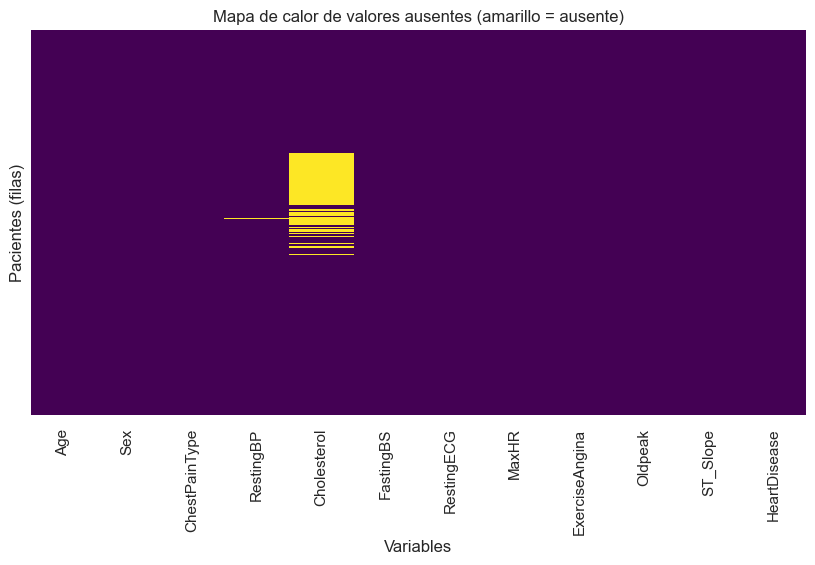

In [10]:
# TODO: heart_diag con los ceros como NaN
heart_diag = heart.copy()
heart_diag[['Cholesterol', 'RestingBP']] = heart_diag[['Cholesterol', 'RestingBP']].replace(0, np.nan)

# TODO: informe_inspeccion(heart_diag)
display(informe_inspeccion(heart_diag))

# TODO: mapa de calor de ausentes
plt.figure(figsize=(10, 5))
sns.heatmap(heart_diag.isna(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Mapa de calor de valores ausentes (amarillo = ausente)')
plt.xlabel('Variables')
plt.ylabel('Pacientes (filas)')
plt.show()

**Preguntas:**

1. ¿Está equilibrada la variable objetivo? Un «modelo» que dijera siempre *enfermo*, ¿qué porcentaje de aciertos tendría?
2. ¿Qué porcentaje de pacientes tiene el colesterol **ausente** en realidad?
3. En el mapa de calor, ¿los ausentes aparecen repartidos al azar o agrupados? ¿Encaja con lo que viste en el ejercicio 1.3?

*Escribe aquí tus respuestas:*

1. Está bastante equilibrada, hay un 55,34% de enfermos y un 44,66% de sanos. Un modelo que dijera siempre enfermo acertaría un 55,34% de las veces.
2. En realidad el colesterol está ausente en 172 pacientes, que son el 18,74% del total.
3. Aparecen agrupados, no al azar. Casi todos salen juntos en un bloque de filas. Si encaja con lo que vi en el 1.3, porque en el gráfico los ceros también estaban juntos, así que seguramente son de un hospital que no midió el colesterol.

---
# Sesión 2 — Análisis de variables y relaciones

## Ejercicio 2.1 — Variables numéricas: distribución y valores atípicos

Trabaja con las cinco variables numéricas continuas: `Age`, `RestingBP`, `Cholesterol`, `MaxHR` y `Oldpeak`.

**Parte A — Estadísticos.**
Construye una tabla con una fila por variable y estas columnas: media, mediana, desviación típica, mínimo, Q1, Q3, máximo, IQR y asimetría (`skew()`). Añade una fila más, `Cholesterol (sin ceros)`, calculada solo con los pacientes con `Cholesterol > 0`.

In [11]:
NUMERICAS = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
# Serie de colesterol solo con los pacientes con Cholesterol > 0
chol_sin_ceros = heart.loc[heart['Cholesterol'] > 0, 'Cholesterol']

# TODO: tabla de estadísticos (incluida la fila «Cholesterol (sin ceros)»)
def estadisticos(serie):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    return {
        'media': serie.mean(),
        'mediana': serie.median(),
        'desviacion tipica': serie.std(),
        'mínimo': serie.min(),
        'Q1': q1,
        'Q3': q3,
        'máximo': serie.max(),
        'IQR': q3 - q1,
        'asimetría': serie.skew()
    }

tabla_estadisticos = pd.DataFrame({var: estadisticos(heart[var]) for var in NUMERICAS}).T
tabla_estadisticos.loc['Cholesterol (sin ceros)'] = estadisticos(chol_sin_ceros)

tabla_estadisticos.round(2)

,media,mediana,desviacion tipica,mínimo,Q1,Q3,máximo,IQR,asimetría
Age,53.51,54.0,9.43,28.0,47.00,60.0,77.0,13.00,-0.20
RestingBP,132.40,130.0,18.51,0.0,120.00,140.0,200.0,20.00,0.18
Cholesterol,198.80,223.0,109.38,0.0,173.25,267.0,603.0,93.75,-0.61
MaxHR,136.81,138.0,25.46,60.0,120.00,156.0,202.0,36.00,-0.14
Oldpeak,0.89,0.6,1.07,-2.6,0.00,1.5,6.2,1.50,1.02
Cholesterol (sin ceros),244.64,237.0,59.15,85.0,207.25,275.0,603.0,67.75,1.24


**Parte B — Histogramas y boxplots.**
En una sola figura de **2 filas × 5 columnas**, dibuja en la fila de arriba el histograma de cada variable (con la curva KDE) y debajo su boxplot horizontal.

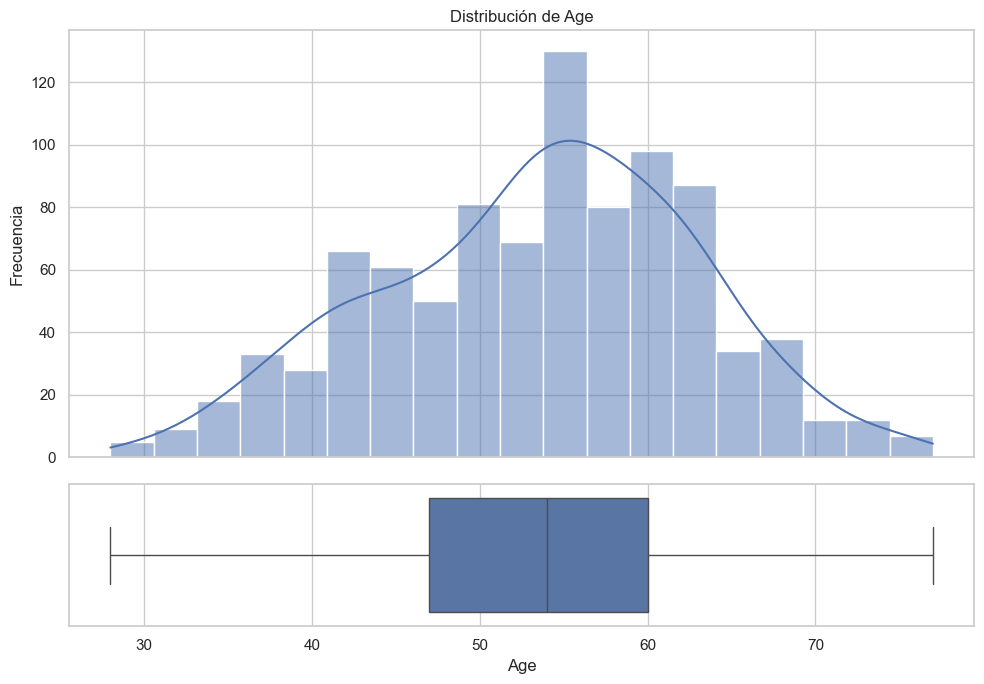

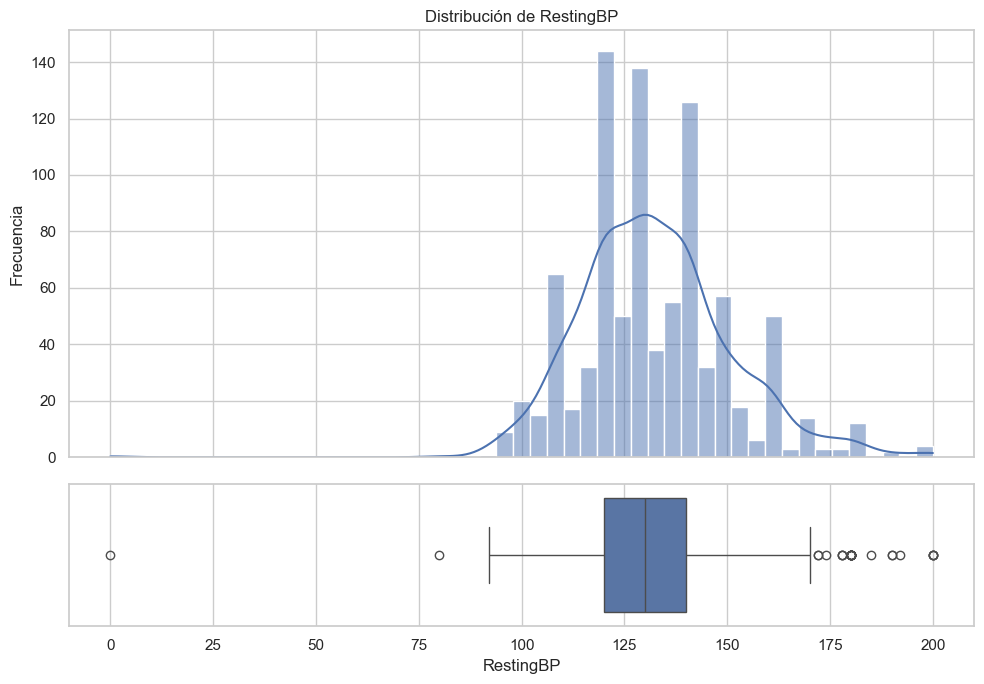

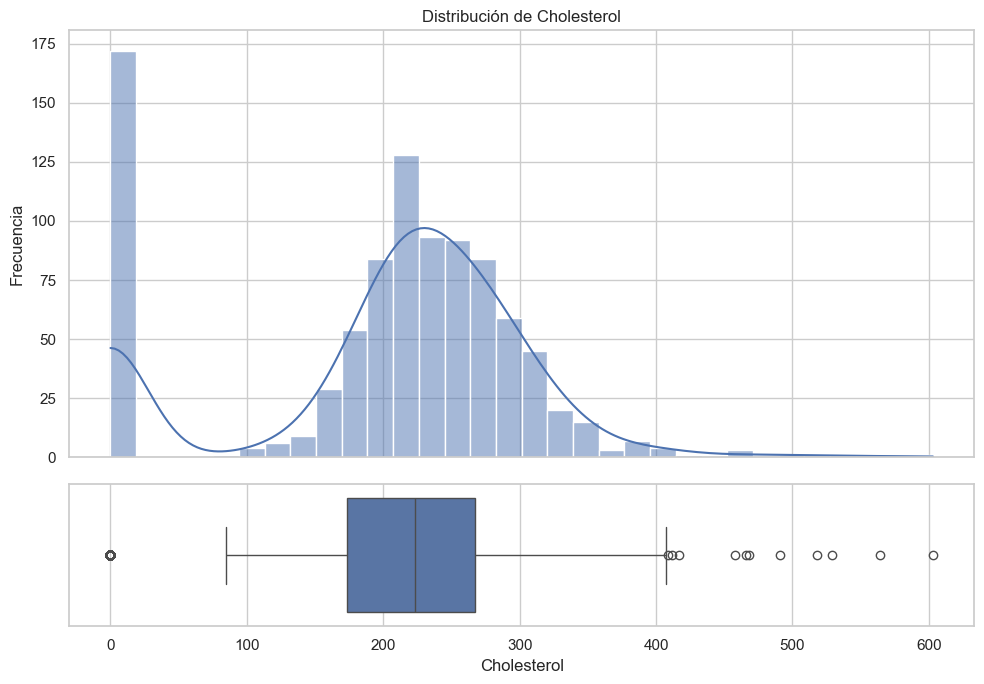

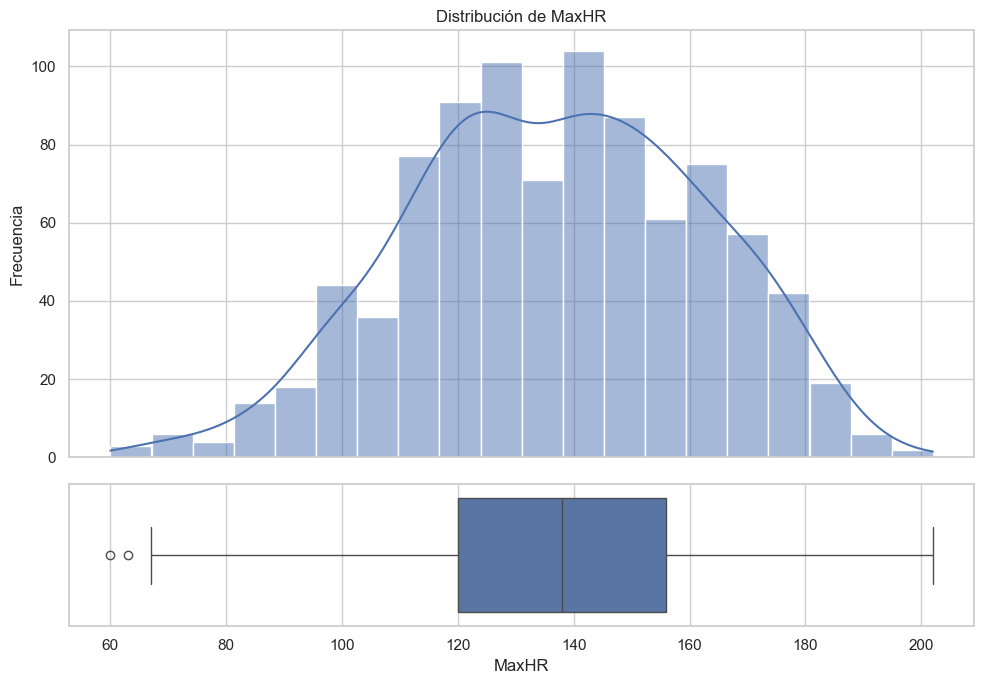

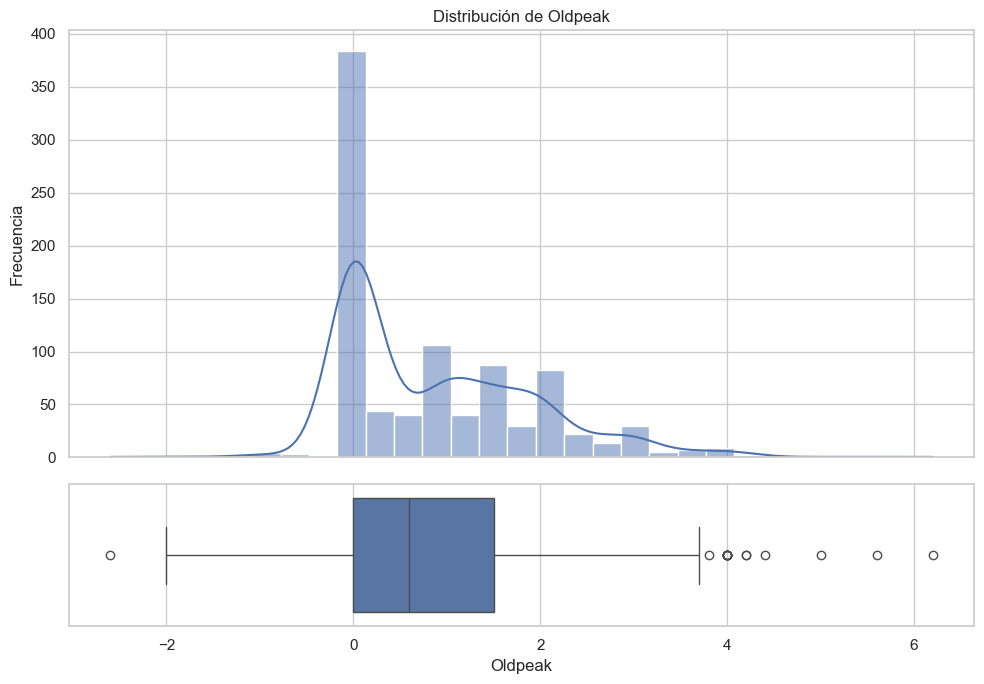

In [12]:
# TODO: histograma y boxplot de cada variable (una figura por variable para que se vean más grandes)
for var in NUMERICAS:
    fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                             gridspec_kw={'height_ratios': [3, 1]})

    sns.histplot(heart[var], kde=True, ax=axes[0])
    axes[0].set_title(f'Distribución de {var}')
    axes[0].set_ylabel('Frecuencia')

    sns.boxplot(x=heart[var], ax=axes[1])
    axes[1].set_xlabel(var)

    plt.tight_layout()
    plt.show()

**Parte C — Atípicos por el criterio IQR.**
Escribe una función `atipicos_iqr(serie)` que devuelva un diccionario con el límite inferior, el límite superior, el número de atípicos y su porcentaje (criterio: fuera de `[Q1 − 1,5·IQR, Q3 + 1,5·IQR]`). Aplícala a las cinco variables y a `Cholesterol` sin ceros, y presenta el resultado como una tabla.

In [13]:
# TODO: función atipicos_iqr y tabla de resultados
def atipicos_iqr(serie):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    limite_inf = q1 - 1.5 * iqr
    limite_sup = q3 + 1.5 * iqr
    es_atipico = (serie < limite_inf) | (serie > limite_sup)
    return {
        'limite_inferior': limite_inf,
        'limite_superior': limite_sup,
        'n_atipicos': es_atipico.sum(),
        'pct_atipicos': es_atipico.mean() * 100
    }

tabla_atipicos = pd.DataFrame({var: atipicos_iqr(heart[var]) for var in NUMERICAS}).T
tabla_atipicos.loc['Cholesterol (sin ceros)'] = atipicos_iqr(chol_sin_ceros)

tabla_atipicos.round(2)

,limite_inferior,limite_superior,n_atipicos,pct_atipicos
Age,27.50,79.50,0.0,0.00
RestingBP,90.00,170.00,28.0,3.05
Cholesterol,32.62,407.62,183.0,19.93
MaxHR,66.00,210.00,2.0,0.22
Oldpeak,-2.25,3.75,16.0,1.74
Cholesterol (sin ceros),105.62,376.62,23.0,3.08


**Preguntas:**

1. ¿Qué variables tienen una distribución asimétrica? ¿Hacia qué lado? Compruébalo comparando media y mediana.
2. ¿Cómo cambian la media, la desviación típica y el número de atípicos de `Cholesterol` al quitar los ceros? ¿Qué cálculo de los dos es el correcto?
3. Mira los atípicos de cada variable. ¿Cuáles crees que son **errores** y cuáles son **valores extremos reales** que hay que conservar? Pon al menos un ejemplo de cada tipo.

*Escribe aquí tus respuestas:*

1. Oldpeak es asimétrica hacia la derecha (asimetría 1,02) y su media (0,89) es mayor que la mediana (0,6). Cholesterol es asimétrica hacia la izquierda (-0,61) y su media (198,80) es menor que la mediana (223), pero eso es por los ceros. En las demás la media y la mediana son parecidas.
2. Al quitar los ceros la media sube de 198,80 a 244,64, la desviación típica baja de 109,38 a 59,15 y los atípicos pasan de 183 a 23. El cálculo correcto es el de sin ceros, porque los ceros no son valores reales, son datos que faltan
3. Son errores los ceros de Cholesterol y el 0 de RestingBP, porque no pueden darse en un paciente vivo. Valores extremos reales que conservaría son un Oldpeak de 6,2, un colesterol de 603 o un MaxHR de 60, que son raros pero posibles.

## Ejercicio 2.2 — Variables categóricas: frecuencias

Trabaja con las seis variables categóricas o binarias: `Sex`, `ChestPainType`, `FastingBS`, `RestingECG`, `ExerciseAngina` y `ST_Slope`.

**Parte A — Tablas de frecuencias.**
Para cada variable, muestra una tabla con la frecuencia absoluta (`n`) y la relativa (`%`, con un decimal).

In [14]:
CATEGORICAS = ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

# TODO: tabla de frecuencias de cada variable
for var in CATEGORICAS:
    tabla = pd.DataFrame({
        'n': heart[var].value_counts(),
        '%': (heart[var].value_counts(normalize=True) * 100).round(1)
    })
    print(f'--- Frecuencias de {var} ---')
    display(tabla)

--- Frecuencias de Sex ---


,n,%
Sex,,
M,725,79.0
F,193,21.0


--- Frecuencias de ChestPainType ---


,n,%
ChestPainType,,
ASY,496,54.0
NAP,203,22.1
ATA,173,18.8
TA,46,5.0


--- Frecuencias de FastingBS ---


,n,%
FastingBS,,
False,704,76.7
True,214,23.3


... (2 outputs left out)

--- Frecuencias de ExerciseAngina ---


,n,%
ExerciseAngina,,
N,547,59.6
Y,371,40.4


--- Frecuencias de ST_Slope ---


,n,%
ST_Slope,,
Flat,460,50.1
Up,395,43.0
Down,63,6.9


**Parte B — Gráficos de barras.**
En una figura de **2 × 3**, dibuja un gráfico de barras por variable. Las variables nominales, ordenadas de mayor a menor frecuencia; las ordinales, en su orden natural. Escribe el porcentaje encima de cada barra (pista: `ax.bar_label()`).

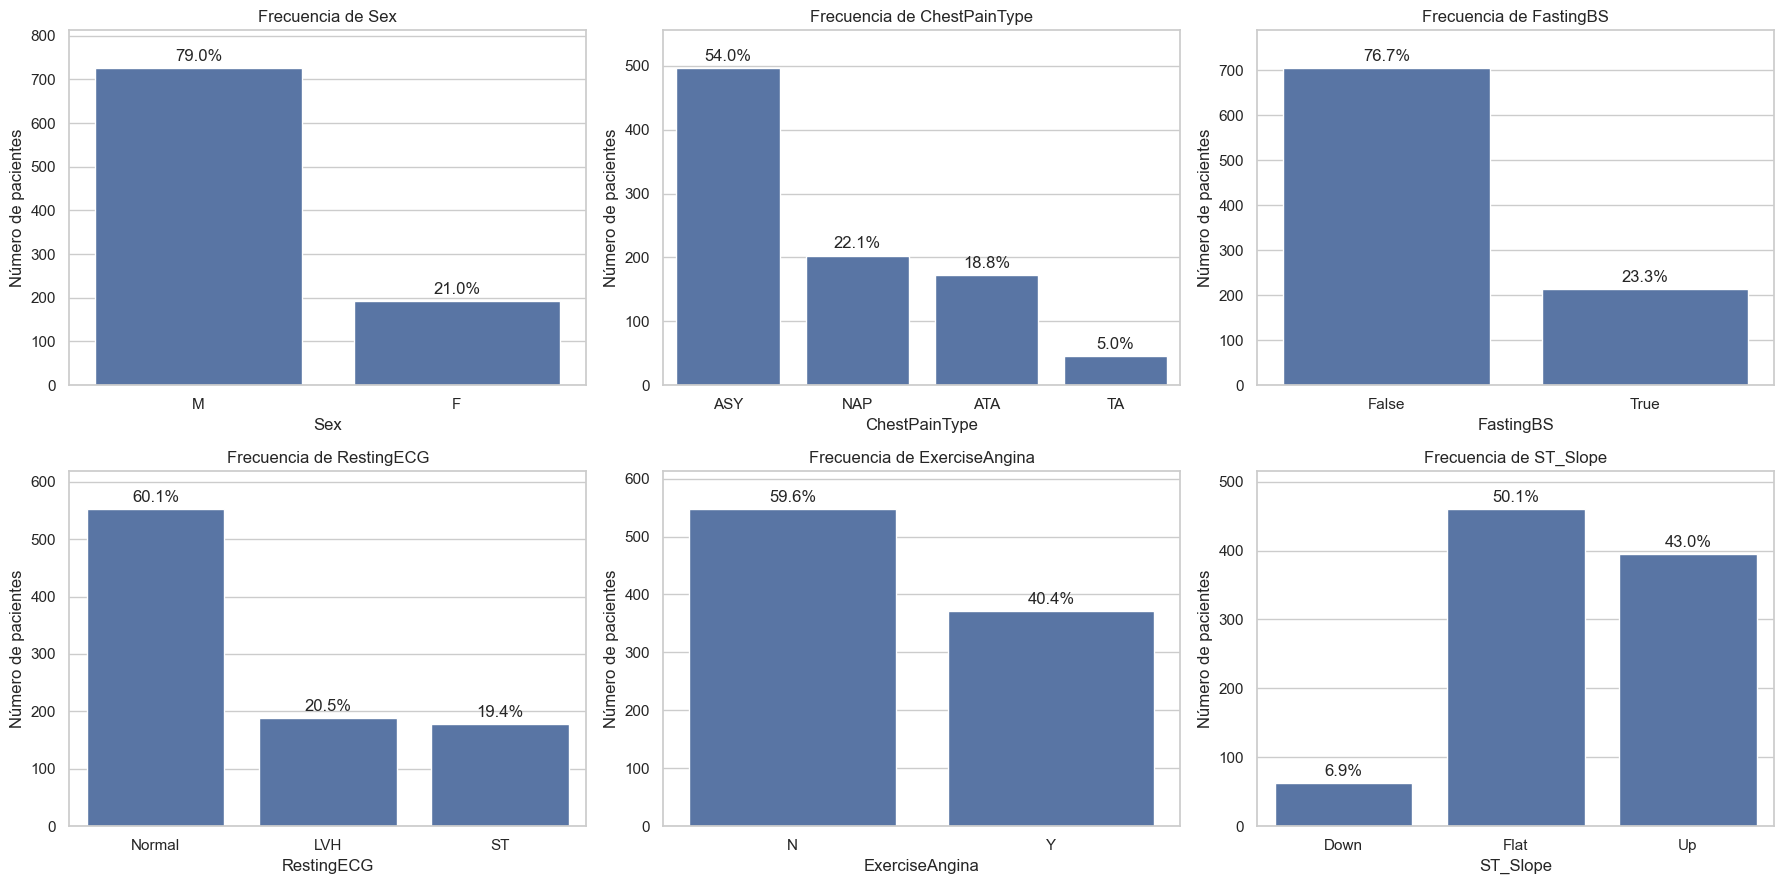

In [15]:
# TODO: figura 2×3 con gráficos de barras
# Orden de cada variable: ordinales y binaria en su orden natural, nominales de mayor a menor frecuencia
ORDEN_NATURAL = {
    'FastingBS': sorted(heart['FastingBS'].unique()),
    'ST_Slope': ['Down', 'Flat', 'Up']
}

fig, axes = plt.subplots(2, 3, figsize=(18, 9))

for ax, var in zip(axes.flatten(), CATEGORICAS):
    if var in ORDEN_NATURAL:
        orden = ORDEN_NATURAL[var]
    else:
        orden = heart[var].value_counts().index

    sns.countplot(x=var, data=heart, order=orden, ax=ax)

    # Porcentaje encima de cada barra
    porcentajes = heart[var].value_counts(normalize=True).reindex(orden) * 100
    ax.bar_label(ax.containers[0], labels=[f'{p:.1f}%' for p in porcentajes], padding=3)

    ax.set_title(f'Frecuencia de {var}')
    ax.set_xlabel(var)
    ax.set_ylabel('Número de pacientes')
    ax.margins(y=0.12)

plt.tight_layout()
plt.show()

**Preguntas:**

1. ¿Qué categorías tienen menos del 10 % de los casos? ¿Qué problema pueden dar al entrenar un modelo?
2. ¿Qué porcentaje de los pacientes son mujeres? ¿Es representativo de la población? ¿Qué consecuencias puede tener para un modelo que se use después con mujeres?
3. La categoría más frecuente de `ChestPainType` es `ASY` (asintomático). ¿Te sorprende en un dataset de pacientes estudiados por sospecha de enfermedad cardiaca? Plantea una explicación.

*Escribe aquí tus respuestas:*

1. Tienen menos del 10% la categoría TA de ChestPainType (5,0%) y Down de ST_Slope (6,9%). El problema es que hay muy pocos ejemplos y el modelo no aprende bien de ellas
2. Un 21% son mujeres (193 de 918). No es representativo, porque en la población general son más o menos la mitad. Un modelo con tan pocas mujeres va a funcionar peor con ellas. Además solo el 25,9% de las mujeres está enferma frente al 63,2% de los hombres, y el modelo podría aprender que ser mujer es estar sano.
3. Si sorprende un poco, porque se esperaría que los pacientes tuvieran dolor. Mi explicación es que asintomático no es lo mismo que sano: hay gente que tiene la enfermedad sin notar dolor y se les hace la prueba por otros factores de riesgo. De hecho el 79% de los ASY está enfermo

## Ejercicio 2.3 — Variables categóricas frente a la variable objetivo

**Parte A — Tasa de enfermedad por categoría.**
Para cada variable de `CATEGORICAS`, calcula el número de pacientes y el **porcentaje de enfermos** (`HeartDisease = 1`) en cada categoría. Muestra también la tabla de contingencia de `ChestPainType` × `HeartDisease` con los totales (`margins=True`), primero en valores absolutos y después en porcentaje por fila.

In [16]:
# TODO: tasa de enfermedad por categoría
tasas = {}
for var in CATEGORICAS:
    tabla = heart.groupby(var, observed=True)['HeartDisease'].agg(['count', 'mean'])
    tabla.columns = ['pacientes', '% enfermos']
    tabla['% enfermos'] = (tabla['% enfermos'] * 100).round(1)
    tasas[var] = tabla
    print(f'--- {var} ---')
    display(tabla)

--- Sex ---


,pacientes,% enfermos
Sex,,
F,193,25.9
M,725,63.2


--- ChestPainType ---


,pacientes,% enfermos
ChestPainType,,
ASY,496,79.0
ATA,173,13.9
NAP,203,35.5
TA,46,43.5


--- FastingBS ---


,pacientes,% enfermos
FastingBS,,
False,704,48.0
True,214,79.4


... (2 outputs left out)

--- ExerciseAngina ---


,pacientes,% enfermos
ExerciseAngina,,
N,547,35.1
Y,371,85.2


--- ST_Slope ---


,pacientes,% enfermos
ST_Slope,,
Down,63,77.8
Flat,460,82.8
Up,395,19.7


In [17]:
# TODO: crosstab ChestPainType × HeartDisease (absoluta y en % por fila)
crosstab_absoluta = pd.crosstab(heart['ChestPainType'], heart['HeartDisease'], margins=True, margins_name='Total')
crosstab_absoluta

HeartDisease,False,True,Total
ChestPainType,,,
ASY,104,392,496
ATA,149,24,173
NAP,131,72,203
TA,26,20,46
Total,410,508,918


In [18]:
crosstab_porcentaje = pd.crosstab(heart['ChestPainType'], heart['HeartDisease'], normalize='index', margins=True, margins_name='Total') * 100
crosstab_porcentaje.round(1)

HeartDisease,False,True
ChestPainType,,
ASY,21.0,79.0
ATA,86.1,13.9
NAP,64.5,35.5
TA,56.5,43.5
Total,44.7,55.3


**Parte B — Gráfico.**
En una figura de **2 × 3**, dibuja para cada variable un gráfico de barras con el **porcentaje de enfermos** por categoría. Añade en todos los gráficos una línea horizontal discontinua con el porcentaje de enfermos de todo el dataset.

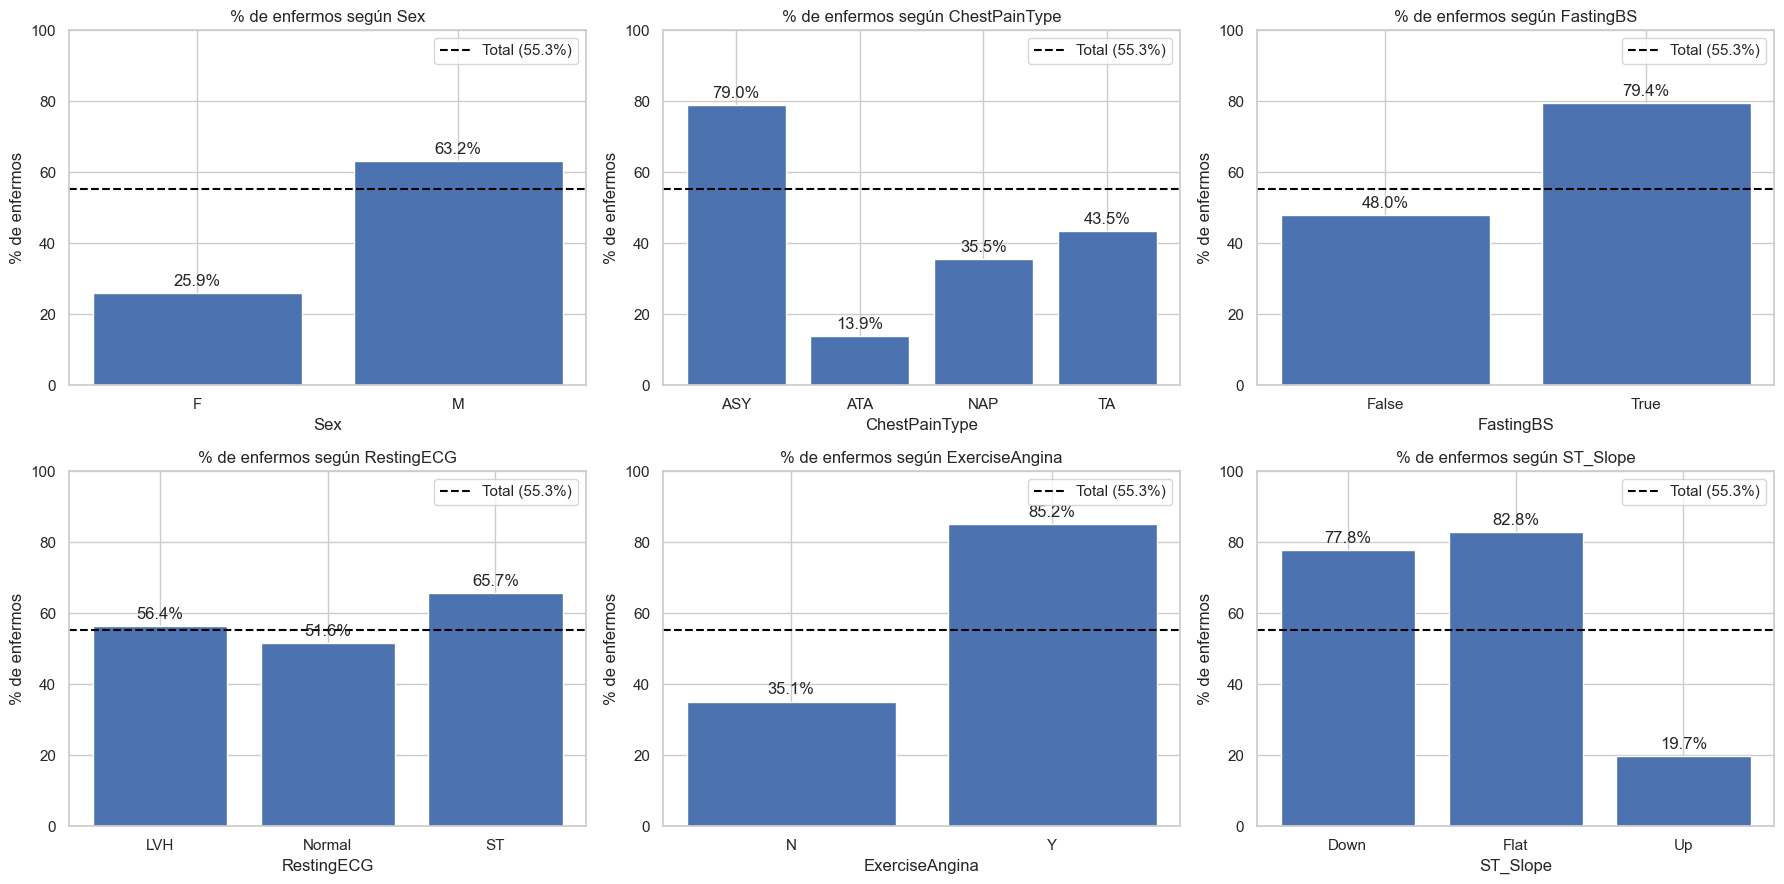

In [19]:
# TODO: figura 2×3 con la tasa de enfermedad por categoría
pct_global = heart['HeartDisease'].mean() * 100

fig, axes = plt.subplots(2, 3, figsize=(18, 9))

for ax, var in zip(axes.flatten(), CATEGORICAS):
    datos = tasas[var]
    ax.bar(datos.index.astype(str), datos['% enfermos'])
    ax.bar_label(ax.containers[0], labels=[f'{v:.1f}%' for v in datos['% enfermos']], padding=3)
    ax.axhline(pct_global, color='black', linestyle='--', label=f'Total ({pct_global:.1f}%)')
    ax.set_title(f'% de enfermos según {var}')
    ax.set_xlabel(var)
    ax.set_ylabel('% de enfermos')
    ax.set_ylim(0, 100)
    ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

**Parte C — Ranking.**
Para cada variable, calcula la diferencia (en puntos porcentuales) entre la categoría con **más** enfermos y la que tiene **menos**. Ordena las variables de mayor a menor diferencia.

In [20]:
# TODO: ranking de variables categóricas
ranking = pd.DataFrame({
    var: {
        'categoría con más enfermos': tasas[var]['% enfermos'].idxmax(),
        'categoría con menos enfermos': tasas[var]['% enfermos'].idxmin(),
        'diferencia (puntos porcentuales)': tasas[var]['% enfermos'].max() - tasas[var]['% enfermos'].min()
    } for var in CATEGORICAS
}).T

ranking.sort_values('diferencia (puntos porcentuales)', ascending=False)

,categoría con más enfermos,categoría con menos enfermos,diferencia (puntos porcentuales)
ChestPainType,ASY,ATA,65.1
ST_Slope,Flat,Up,63.1
ExerciseAngina,Y,N,50.1
Sex,M,F,37.3
FastingBS,True,False,31.4
RestingECG,ST,Normal,14.1


**Preguntas:**

1. ¿Qué tres variables categóricas parecen más relacionadas con la enfermedad? ¿Y cuál menos?
2. Los pacientes **asintomáticos** (`ASY`) son los que más enferman. ¿Cómo lo explicas? (Recuerda quiénes son estos pacientes y por qué se les hizo la prueba.)
3. La categoría `TA` tiene solo 46 pacientes. ¿Te fías igual de su porcentaje de enfermos que del de `ASY`, con 496? ¿Por qué?

*Escribe aquí tus respuestas:*

1. Las más relacionadas son ChestPainType (65,1 puntos de diferencia), ST_Slope (63,1) y ExerciseAngina (50,1). La menos relacionada es RestingECG, con solo 14,1 puntos.
2. Los asintomáticos son pacientes que no tienen dolor pero a los que se les hizo la prueba igualmente, seguramente porque tenían otros factores de riesgo o alguna prueba alterada. La enfermedad puede darse sin dolor. Por eso el 79% de los ASY está enfermo, y en cambio ATA (angina atípica) solo tiene un 13,9%.
3. No me fío igual. TA tiene solo 46 pacientes (20 enfermos), y con tan pocos el porcentaje cambia mucho si cambian unos pocos pacientes. Con los 496 de ASY el porcentaje es mucho más estable

## Ejercicio 2.4 — Correlaciones y la paradoja del colesterol

**Parte A — Matriz de correlación.**
Calcula la matriz de correlación de Pearson de las columnas numéricas (incluidas `FastingBS` y `HeartDisease`) y dibújala como mapa de calor: con los valores escritos, paleta divergente centrada en 0 y **solo el triángulo inferior** (pista: `np.triu` para crear la máscara).

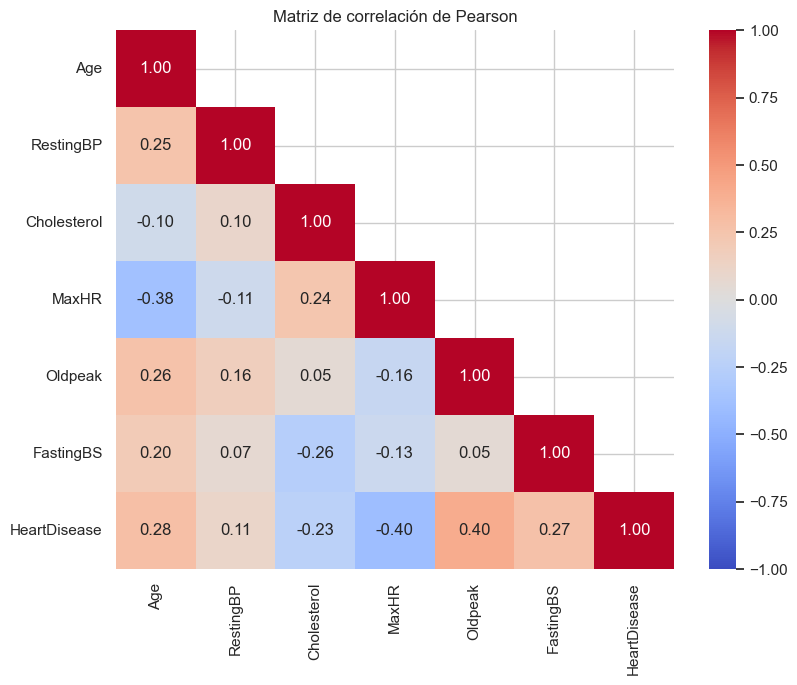

In [21]:
# TODO: matriz de correlación y heatmap
columnas_corr = NUMERICAS + ['FastingBS', 'HeartDisease']
matriz_corr = heart[columnas_corr].astype(float).corr()

# Máscara para quedarnos solo con el triángulo inferior
mascara = np.triu(np.ones_like(matriz_corr, dtype=bool), k=1)

plt.figure(figsize=(9, 7))
sns.heatmap(matriz_corr, mask=mascara, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Matriz de correlación de Pearson')
plt.show()

**Parte B — Correlación con la variable objetivo.**
Muestra la correlación de cada variable con `HeartDisease`, ordenada de mayor a menor **valor absoluto**.

In [22]:
# TODO: correlaciones con HeartDisease ordenadas por valor absoluto
corr_objetivo = matriz_corr['HeartDisease'].drop('HeartDisease')
corr_objetivo = corr_objetivo.reindex(corr_objetivo.abs().sort_values(ascending=False).index)
corr_objetivo.round(3)

Oldpeak        0.404
MaxHR         -0.400
Age            0.282
FastingBS      0.267
Cholesterol   -0.233
RestingBP      0.108
Name: HeartDisease, dtype: float64

**Parte C — La paradoja del colesterol.**

1. Calcula la correlación entre `Cholesterol` y `HeartDisease` con **todos** los pacientes y solo con los que tienen `Cholesterol > 0`.
2. Calcula el porcentaje de enfermos entre los pacientes con `Cholesterol == 0` y entre los que tienen `Cholesterol > 0`.

In [23]:
# TODO: correlación con y sin ceros
enfermo = heart['HeartDisease'].astype(int)
corr_todos = heart['Cholesterol'].corr(enfermo)
con_colesterol = heart['Cholesterol'] > 0
corr_sin_ceros = heart.loc[con_colesterol, 'Cholesterol'].corr(enfermo[con_colesterol])
print(f'Correlación Cholesterol - HeartDisease con todos los pacientes: {corr_todos:.3f}')
print(f'Correlación Cholesterol - HeartDisease sin los ceros: {corr_sin_ceros:.3f}')
print()

# TODO: porcentaje de enfermos según Cholesterol == 0
pct_cero = enfermo[~con_colesterol].mean() * 100
pct_no_cero = enfermo[con_colesterol].mean() * 100
print(f'% de enfermos con Cholesterol == 0: {pct_cero:.1f} % ({(~con_colesterol).sum()} pacientes)')
print(f'% de enfermos con Cholesterol > 0: {pct_no_cero:.1f} % ({con_colesterol.sum()} pacientes)')

Correlación Cholesterol - HeartDisease con todos los pacientes: -0.233
Correlación Cholesterol - HeartDisease sin los ceros: 0.104

% de enfermos con Cholesterol == 0: 88.4 % (172 pacientes)
% de enfermos con Cholesterol > 0: 47.7 % (746 pacientes)


**Preguntas:**

1. Interpreta el signo de la correlación de `MaxHR` y de `Oldpeak` con la enfermedad.
2. Con todos los datos, parece que **a más colesterol, menos enfermedad**. ¿Es verdad? Explica qué está pasando con los resultados de la Parte C.
3. Si entrenaras un modelo con los datos tal como están, ¿qué «aprendería» de `Cholesterol`? ¿Funcionaría bien en un hospital que siempre mide el colesterol?
4. `FastingBS` y `HeartDisease` solo valen 0 o 1. ¿Tiene sentido incluirlas en una correlación de Pearson? ¿Qué mide en ese caso?

*Escribe aquí tus respuestas:*

1. MaxHR tiene una correlación de -0,40, así que cuanta más frecuencia máxima alcanza el paciente menos probable es que esté enfermo. Oldpeak tiene +0,40, así que cuanto mayor es el Oldpeak más probable es que esté enfermo
2. No es verdad. Con todos los pacientes sale -0,233, pero sin los ceros sale +0,104. Entre los pacientes con colesterol 0 el 88,4% está enfermo, y entre los que si tienen colesterol el 47,7%. Los ceros son datos que faltan y resulta que son de pacientes que están casi todos enfermos, y eso hace que parezca que menos colesterol es más enfermedad
3. Aprendería que un colesterol de 0 significa enfermo, y eso no es real. En un hospital que siempre mide el colesterol no funcionaría bien, porque ahí nunca habría ceros y el modelo se equivocaría.
4. Se puede calcular, pero no es lo ideal porque son variables binarias. En este caso mide si las dos tienden a ser 1 a la vez. Sale 0,27, una relación positiva débil: los que tienen la glucosa alta suelen estar enfermos más veces.

## Ejercicio 2.5 — Relaciones a la vista: dispersión, violines y pairplot

**Parte A — Edad y frecuencia cardiaca máxima.**
Dibuja `MaxHR` frente a `Age`, coloreando por `HeartDisease`, con una recta de regresión para cada grupo (pista: `sns.lmplot`).

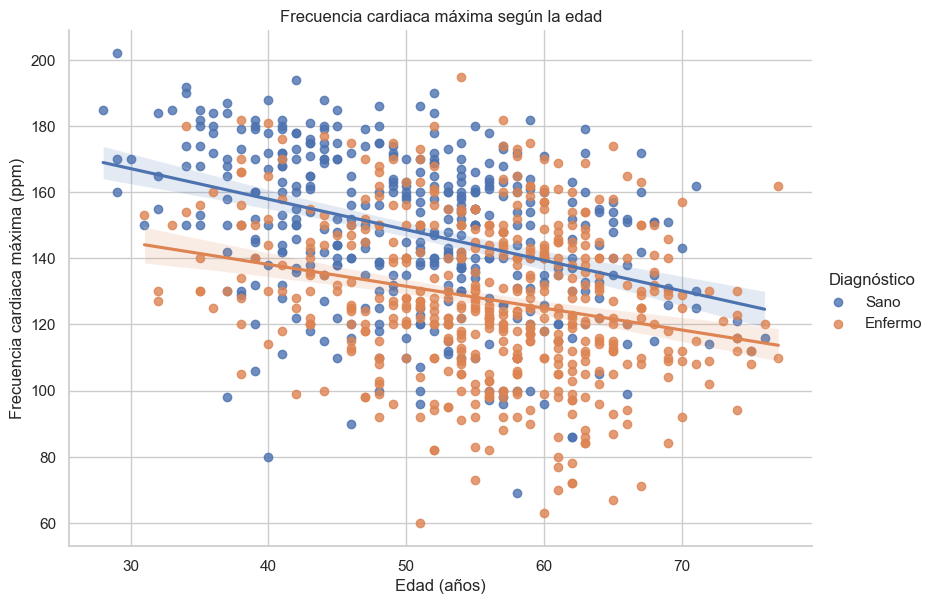

In [24]:
# TODO: MaxHR frente a Age con recta por grupo
heart_plot = heart.copy()
heart_plot['Diagnóstico'] = heart_plot['HeartDisease'].map({False: 'Sano', True: 'Enfermo'})

sns.lmplot(data=heart_plot, x='Age', y='MaxHR', hue='Diagnóstico', height=6, aspect=1.4)
plt.title('Frecuencia cardiaca máxima según la edad')
plt.xlabel('Edad (años)')
plt.ylabel('Frecuencia cardiaca máxima (ppm)')
plt.show()

**Parte B — Violines.**
En una figura de 1 × 2, dibuja un violinplot de `MaxHR` y otro de `Oldpeak` según `HeartDisease`, separando por sexo dentro de cada violín (`hue='Sex', split=True`).

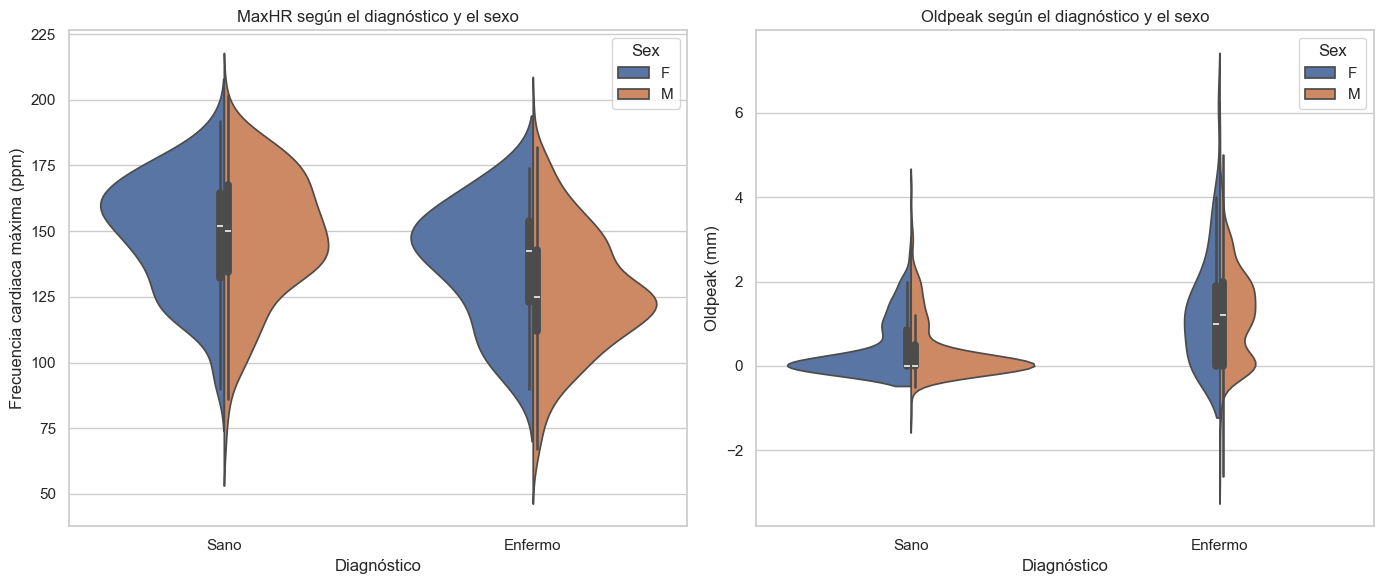

In [25]:
# TODO: violinplots de MaxHR y Oldpeak
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, var in zip(axes, ['MaxHR', 'Oldpeak']):
    sns.violinplot(data=heart_plot, x='Diagnóstico', y=var, hue='Sex', split=True, order=['Sano', 'Enfermo'], ax=ax)
    ax.set_title(f'{var} según el diagnóstico y el sexo')
    ax.set_xlabel('Diagnóstico')

axes[0].set_ylabel('Frecuencia cardiaca máxima (ppm)')
axes[1].set_ylabel('Oldpeak (mm)')
plt.tight_layout()
plt.show()

**Parte C — Pairplot.**
Dibuja un `pairplot` de `Age`, `RestingBP`, `Cholesterol`, `MaxHR` y `Oldpeak` coloreado por `HeartDisease`, mostrando solo el triángulo inferior (`corner=True`). Usa **solo los pacientes con `Cholesterol > 0` y `RestingBP > 0`**.

Pacientes que quedan: 746


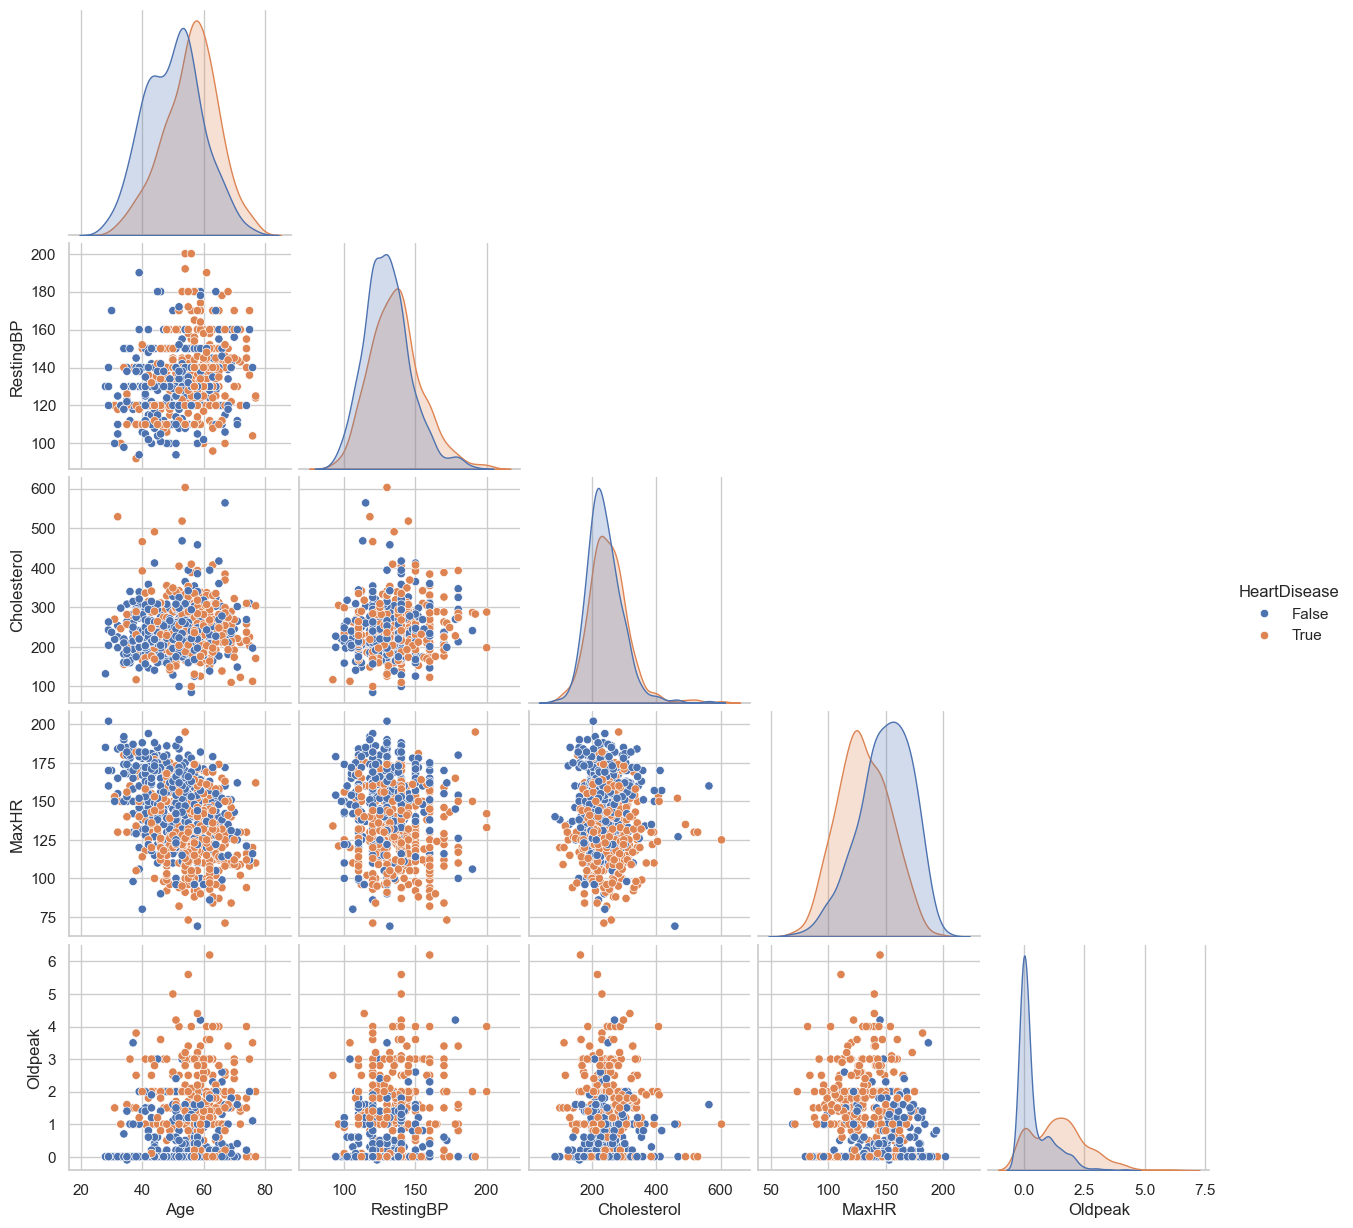

In [26]:
# TODO: pairplot sin los ceros
sin_ceros = heart[(heart['Cholesterol'] > 0) & (heart['RestingBP'] > 0)]
print('Pacientes que quedan:', len(sin_ceros))

sns.pairplot(sin_ceros, vars=NUMERICAS, hue='HeartDisease', corner=True)
plt.show()

**Preguntas:**

1. ¿Qué le pasa a la frecuencia cardiaca máxima al aumentar la edad? ¿Ocurre igual en sanos y en enfermos?
2. ¿Ves diferencias entre hombres y mujeres en los violines? ¿Cuál de las dos variables separa mejor a sanos y enfermos?
3. En el pairplot, ¿qué par de variables separa mejor las dos clases? ¿Hay alguna variable que no parezca aportar casi nada?
4. ¿Por qué hemos quitado los ceros para el pairplot? ¿Cómo se vería si no lo hubiéramos hecho?

*Escribe aquí tus respuestas:*

1. Al aumentar la edad la frecuencia cardiaca máxima baja (correlación de -0,38). Ocurre igual en sanos y enfermos (-0,38 en sanos y -0,25 en enfermos), pero los enfermos siempre están por debajo
2. Si, en los enfermos las mujeres tienen un MaxHR más alto que los hombres (mediana de 142,5 frente a 125), y en los sanos son parecidos. La variable que mejor separa a sanos y enfermos es Oldpeak, porque los sanos están casi todos en 0 y los enfermos tienen una mediana de 1,2.
3. El par que mejor separa debería ser Oldpeak con MaxHR, porque son las dos que más se relacionan con la enfermedad. Cholesterol y RestingBP casi no aportan nada, tienen una correlación de solo 0,10 y 0,17 con la enfermedad.
4. Porque los ceros son datos que faltan y no valores reales. Si no los hubiéramos quitado saldría una fila de puntos pegados al 0 en Cholesterol y RestingBP, que deforma los gráficos y la relación entre variables

---
# Sesión 3 — Visualización y perfilado automático

## Ejercicio 3.1 — Dashboard del riesgo cardiaco

Crea con `gridspec` una sola figura (de unos 16 × 9 pulgadas) con **cinco paneles** distribuidos así:

```
┌───────────────────────────────┬──────────────┐
│ 1. Distribución de la edad    │ 2. % enfermos│
│    de sanos y enfermos        │ por tipo de  │
│                               │ dolor        │
├───────────────┬───────────────┼──────────────┤
│ 3. MaxHR      │ 4. % enfermos │ 5. Angina de │
│ sanos vs.     │ por pendiente │ esfuerzo por │
│ enfermos      │ ST            │ diagnóstico  │
└───────────────┴───────────────┴──────────────┘
```

Requisitos:

- Un título general (`fig.suptitle`) y un título en cada panel.
- Ejes con etiquetas en castellano y unidades cuando las haya.
- **Los mismos dos colores** para sanos y enfermos en todos los paneles. Defínelos una vez en un diccionario `COLORES` y úsalo siempre.
- En las leyendas, «Sano» y «Enfermo» en lugar de 0 y 1.
- Las categorías ordinales en su orden.
- Guarda la figura en `dashboard_corazon.png` (`dpi=150`, `bbox_inches='tight'`).

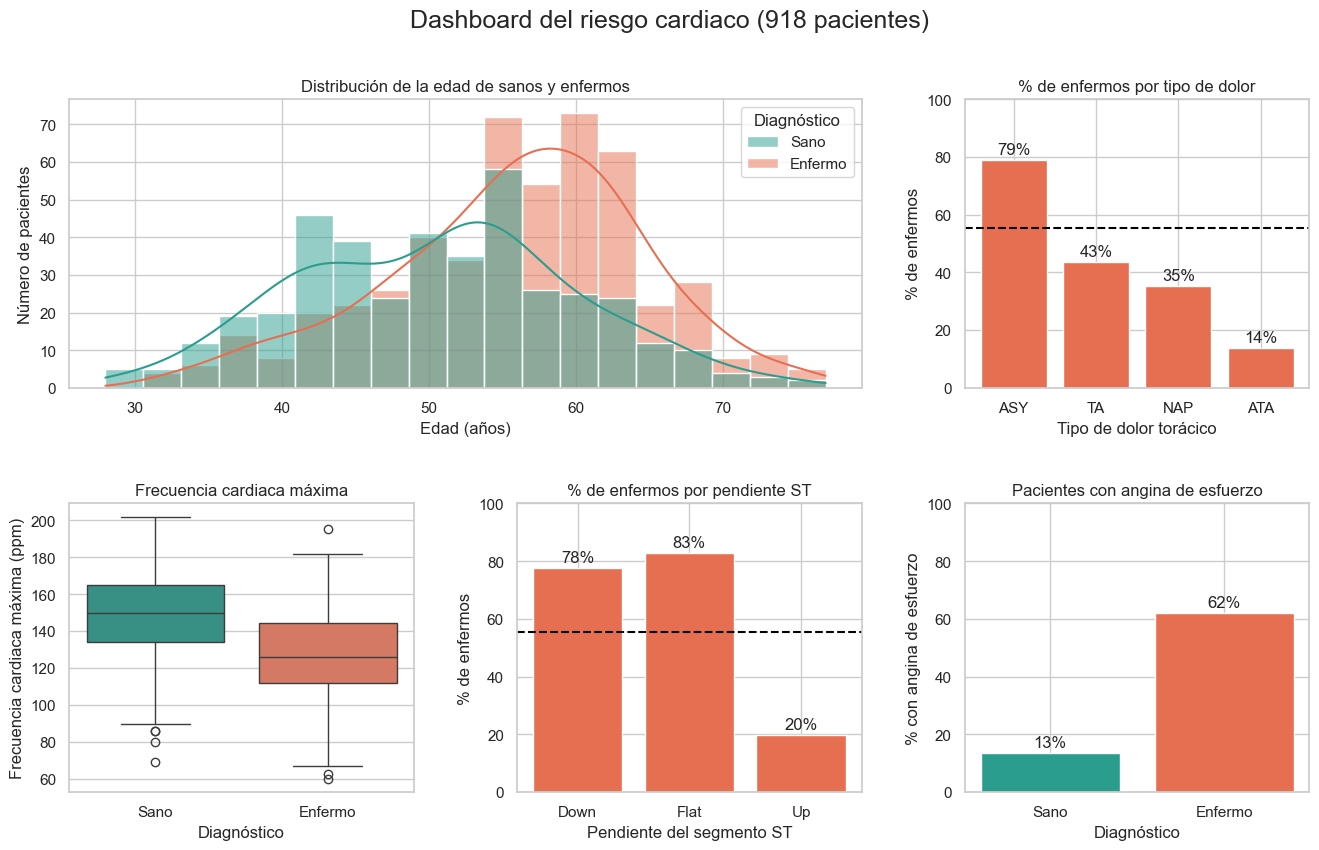

In [27]:
# TODO: dashboard con gridspec
COLORES = {0: '#2a9d8f', 1: '#e76f51'}
NOMBRES = {0: 'Sano', 1: 'Enfermo'}
PALETA = {NOMBRES[k]: COLORES[k] for k in COLORES}

datos = heart.assign(Diagnóstico=heart['HeartDisease'].map({False: 'Sano', True: 'Enfermo'}))
pct_global = heart['HeartDisease'].mean() * 100

fig = plt.figure(figsize=(16, 9))
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.4, wspace=0.3)
fig.suptitle('Dashboard del riesgo cardiaco (918 pacientes)', fontsize=18)

# 1. Distribución de la edad
ax1 = fig.add_subplot(gs[0, 0:2])
sns.histplot(data=datos, x='Age', hue='Diagnóstico', palette=PALETA, hue_order=['Sano', 'Enfermo'], kde=True, ax=ax1)
ax1.set_title('Distribución de la edad de sanos y enfermos')
ax1.set_xlabel('Edad (años)')
ax1.set_ylabel('Número de pacientes')

# 2. % de enfermos por tipo de dolor
ax2 = fig.add_subplot(gs[0, 2])
tasa_dolor = (heart.groupby('ChestPainType', observed=True)['HeartDisease'].mean() * 100).sort_values(ascending=False)
ax2.bar(tasa_dolor.index.astype(str), tasa_dolor.values, color=COLORES[1])
ax2.bar_label(ax2.containers[0], labels=[f'{v:.0f}%' for v in tasa_dolor.values], padding=2)
ax2.axhline(pct_global, color='black', linestyle='--')
ax2.set_title('% de enfermos por tipo de dolor')
ax2.set_xlabel('Tipo de dolor torácico')
ax2.set_ylabel('% de enfermos')
ax2.set_ylim(0, 100)

# 3. MaxHR de sanos y enfermos
ax3 = fig.add_subplot(gs[1, 0])
sns.boxplot(data=datos, x='Diagnóstico', y='MaxHR', order=['Sano', 'Enfermo'], palette=PALETA, hue='Diagnóstico', legend=False, ax=ax3)
ax3.set_title('Frecuencia cardiaca máxima')
ax3.set_xlabel('Diagnóstico')
ax3.set_ylabel('Frecuencia cardiaca máxima (ppm)')

# 4. % de enfermos por pendiente ST (orden natural)
ax4 = fig.add_subplot(gs[1, 1])
tasa_st = (heart.groupby('ST_Slope', observed=True)['HeartDisease'].mean() * 100)
ax4.bar(tasa_st.index.astype(str), tasa_st.values, color=COLORES[1])
ax4.bar_label(ax4.containers[0], labels=[f'{v:.0f}%' for v in tasa_st.values], padding=2)
ax4.axhline(pct_global, color='black', linestyle='--')
ax4.set_title('% de enfermos por pendiente ST')
ax4.set_xlabel('Pendiente del segmento ST')
ax4.set_ylabel('% de enfermos')
ax4.set_ylim(0, 100)

# 5. Angina de esfuerzo por diagnóstico
ax5 = fig.add_subplot(gs[1, 2])
pct_angina = datos.groupby('Diagnóstico')['ExerciseAngina'].apply(lambda s: (s == 'Y').mean() * 100).reindex(['Sano', 'Enfermo'])
ax5.bar(pct_angina.index, pct_angina.values, color=[PALETA[d] for d in pct_angina.index])
ax5.bar_label(ax5.containers[0], labels=[f'{v:.0f}%' for v in pct_angina.values], padding=2)
ax5.set_title('Pacientes con angina de esfuerzo')
ax5.set_xlabel('Diagnóstico')
ax5.set_ylabel('% con angina de esfuerzo')
ax5.set_ylim(0, 100)

fig.savefig('dashboard_corazon.png', dpi=150, bbox_inches='tight')
plt.show()

**Preguntas:**

1. Si solo pudieras enseñar este dashboard durante 30 segundos, ¿cuál sería el mensaje principal?
2. ¿Qué cambiarías si el dashboard fuera para un equipo médico en lugar de para tus compañeros de datos?

*Escribe aquí tus respuestas:*

1. Que la enfermedad aumenta con la edad y que los enfermos se reconocen porque tienen un tipo de dolor ASY, una pendiente ST plana, un MaxHR más bajo y casi todos tienen angina de esfuerzo (un 62% de los enfermos frente a un 13% de los sanos).
2. Pondría los nombres completos de las categorías (por ejemplo angina atípica en vez de ATA), explicaría las unidades y quitaría la curva KDE del histograma. También pondría el número de pacientes de cada grupo.

## Ejercicio 3.2 — Comparar grupos con `catplot`, `displot` y `FacetGrid`

**Parte A.** Con `sns.catplot(kind='bar')`, dibuja la proporción de enfermos por `ChestPainType`, con un panel para cada sexo (`col='Sex'`). Ordena las categorías igual en los dos paneles.

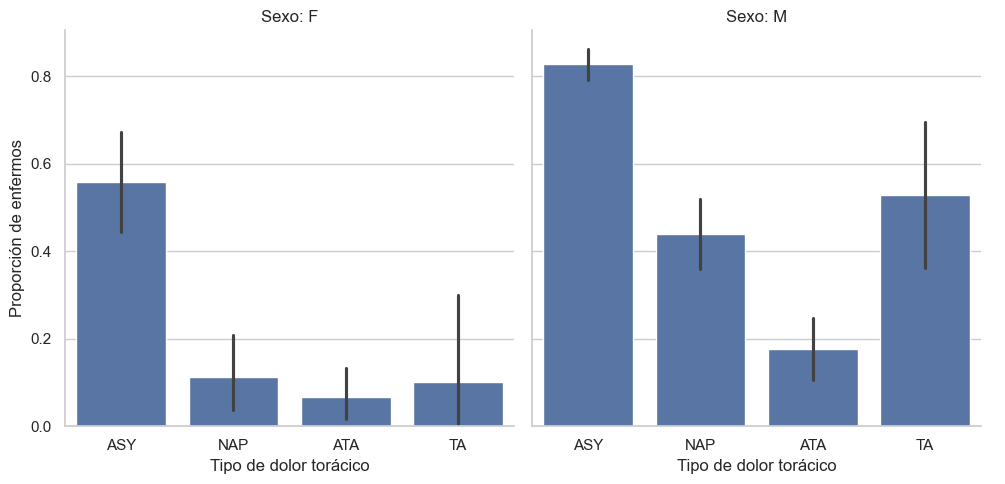

In [28]:
# TODO: catplot de la proporción de enfermos por tipo de dolor y sexo
heart_num = heart.assign(Enfermo=heart['HeartDisease'].astype(int))

g = sns.catplot(data=heart_num, x='ChestPainType', y='Enfermo', col='Sex', kind='bar',
                order=['ASY', 'NAP', 'ATA', 'TA'], height=5, aspect=1)
g.set_axis_labels('Tipo de dolor torácico', 'Proporción de enfermos')
g.set_titles('Sexo: {col_name}')
plt.show()

**Parte B.** Con `sns.displot(kind='kde')`, dibuja la distribución de `MaxHR` de sanos y enfermos, con un panel según tengan o no angina de esfuerzo (`col='ExerciseAngina'`). Usa `common_norm=False`.

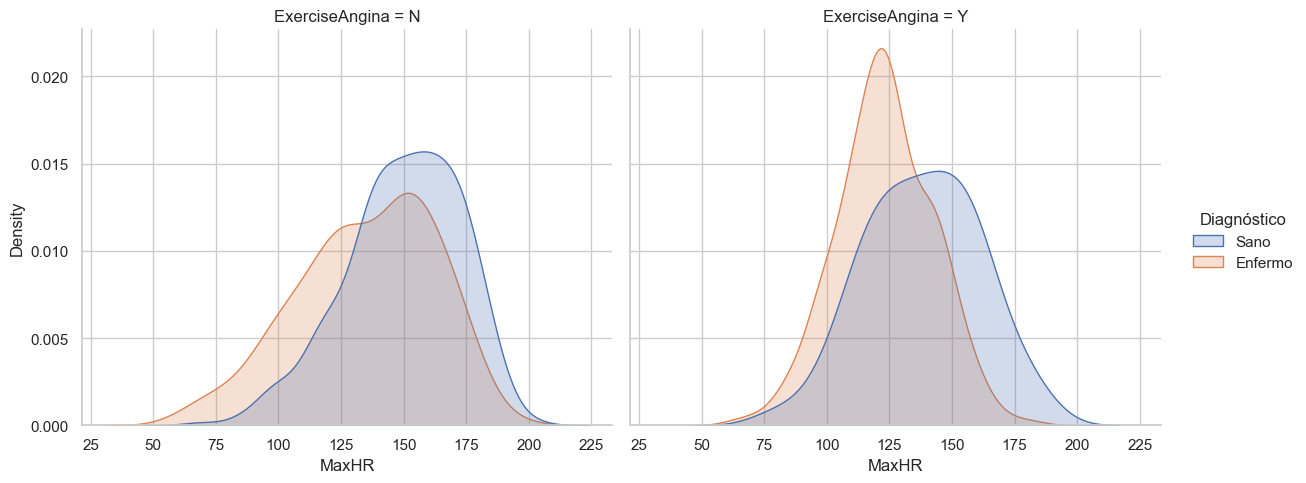

In [29]:
# TODO: displot de MaxHR por ExerciseAngina
sns.displot(data=heart_plot, x='MaxHR', hue='Diagnóstico', col='ExerciseAngina', kind='kde',
            common_norm=False, fill=True, height=5, aspect=1.2)
plt.show()

**Parte C.** Con `sns.FacetGrid`, crea una cuadrícula con una fila por sexo y una columna por `ST_Slope` (en su orden). En cada panel, dibuja `Oldpeak` frente a `Age` coloreando por `HeartDisease`, y añade la leyenda.

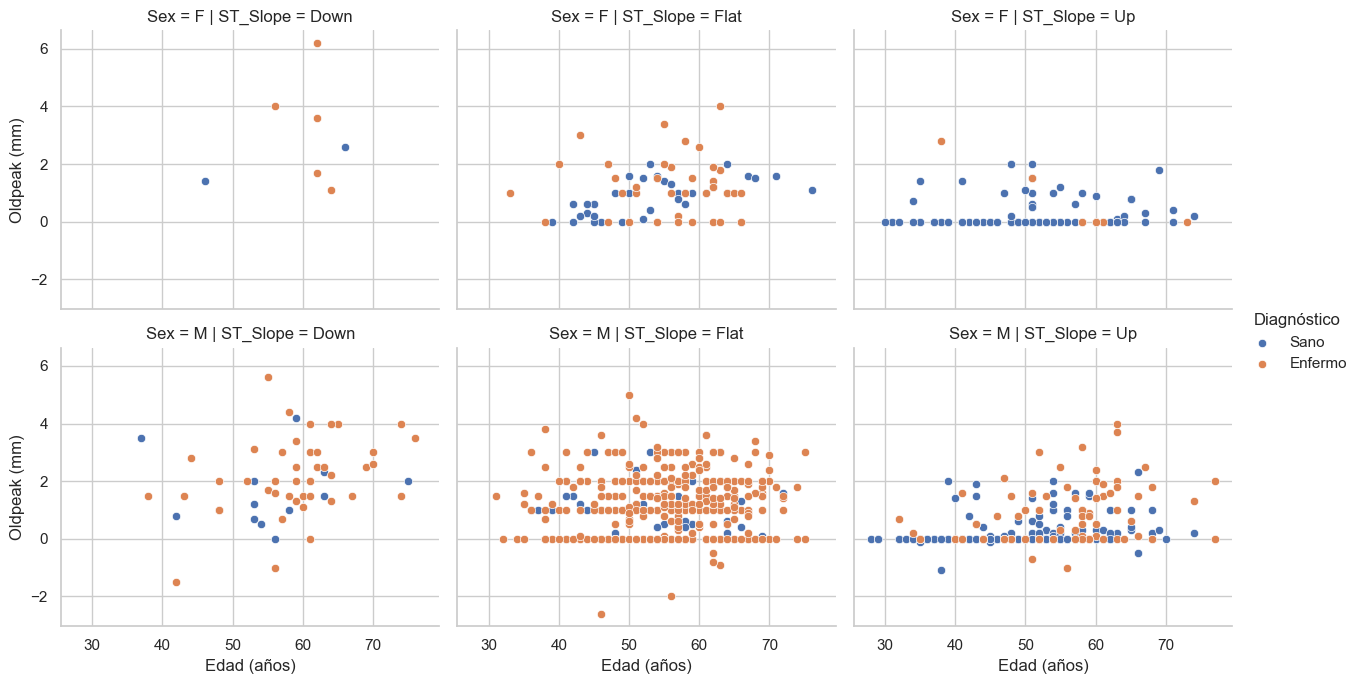

In [30]:
# TODO: FacetGrid Sex × ST_Slope
g = sns.FacetGrid(heart_plot, row='Sex', col='ST_Slope', col_order=['Down', 'Flat', 'Up'], hue='Diagnóstico',
                  hue_order=['Sano', 'Enfermo'], height=3.5, aspect=1.2)
g.map(sns.scatterplot, 'Age', 'Oldpeak')
g.add_legend()
g.set_axis_labels('Edad (años)', 'Oldpeak (mm)')
plt.show()

**Preguntas:**

1. ¿Se mantiene en los dos sexos el efecto del tipo de dolor torácico? ¿Qué representan las barras negras y por qué son más largas en el panel de las mujeres?
2. ¿Qué hace `common_norm=False`? ¿Cómo se vería el gráfico de la Parte B sin ese parámetro?
3. ¿Hay algún panel del `FacetGrid` con tan pocos pacientes que no permita sacar conclusiones? ¿Cuál?

*Escribe aquí tus respuestas:*

1. Si, en los dos sexos ASY es el tipo de dolor con más enfermos (56% en mujeres y 83% en hombres) y ATA uno de los que menos. Las barras negras son el intervalo de confianza del 95%, que indica cuanta incertidumbre hay en ese porcentaje. Son más largas en las mujeres porque hay menos (193), sobre todo en TA que solo tiene 10 mujeres.
2. common_norm=False hace que cada curva se normalice por separado, así cada una tiene área 1 aunque el grupo sea más pequeño. Sin eso se escalarían todas juntas según el tamaño del grupo, y por ejemplo los sanos con angina (solo 55 pacientes) se verían mucho más bajos que los demás
3. El de las mujeres con pendiente Down, que solo tiene 7 pacientes. No se pueden sacar conclusiones con tan pocos

## Ejercicio 3.3 — Perfilado automático con ydata-profiling

**Parte A — Informe completo.**
Genera un informe de perfilado de `heart_raw` con `explorative=True`, guárdalo en `informe_heart.html` y ábrelo en el navegador. Después, imprime la lista de alertas que ha detectado.

> Usamos `heart_raw` (la copia original) para ver qué detecta el informe **sin** ninguna ayuda nuestra.

In [31]:
from ydata_profiling import ProfileReport
import webbrowser

# TODO: informe completo de heart_raw y lista de alertas
informe = ProfileReport(heart_raw, title='Heart Failure Prediction', explorative=True)
informe.to_file('informe_heart.html')
webbrowser.open((Path('informe_heart.html').resolve()).as_uri())

print('Alertas del informe:')
for alerta in informe.get_description().alerts:
    print('-', alerta)

C:\Users\mexpl\AppData\Local\Temp\ipykernel_5940\2947651674.py:1: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 12/12 [00:00<00:00, 684.09it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Alertas del informe:
- [ChestPainType] is highly overall correlated with [HeartDisease]
- [HeartDisease] is highly overall correlated with [ChestPainType] and 1 other fields
- [ST_Slope] is highly overall correlated with [HeartDisease]
- [Cholesterol] has 172 (18.7%) zeros
- [Oldpeak] has 368 (40.1%) zeros


**Parte B — Informe comparativo.**
Genera dos informes en modo `minimal=True`: uno de `heart_raw` y otro de una copia en la que los ceros de `Cholesterol` y `RestingBP` sean `NaN` (puedes reutilizar la idea de `heart_diag`, partiendo de `heart_raw`). Compáralos con `.compare()` y guarda el resultado en `informe_heart_comparativo.html`.

In [32]:
# TODO: informes minimal y comparación
heart_raw_nan = heart_raw.copy()
heart_raw_nan[['Cholesterol', 'RestingBP']] = heart_raw_nan[['Cholesterol', 'RestingBP']].replace(0, np.nan)

informe_original = ProfileReport(heart_raw, title='Original', minimal=True)
informe_nan = ProfileReport(heart_raw_nan, title='Ceros como NaN', minimal=True)

comparacion = informe_original.compare(informe_nan)
comparacion.to_file('informe_heart_comparativo.html')
webbrowser.open((Path('informe_heart_comparativo.html').resolve()).as_uri())

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 12/12 [00:00<00:00, 2003.25it/s]


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 12/12 [00:00<00:00, 1699.53it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

True

**Parte C — ¿Qué ha visto el informe y qué has visto tú?**
Completa la tabla con todos los problemas de calidad que has encontrado en el cuaderno y con todas las alertas del informe:

| Problema o alerta | Variable(s) | ¿Lo detecta el informe? | ¿Lo habías detectado tú? ¿En qué ejercicio? | ¿Es un problema real? |
|---|---|---|---|---|
| 172 ceros (18,7%) | Cholesterol | Sí, como alerta de ceros, pero no dice que sean ausentes | Sí, en el 1.3 y el 1.4 | Sí, son valores ausentes |
| Un 0 imposible | RestingBP | No hay alerta, solo se ve el mínimo en 0 | Sí, en el 1.3 | Sí, es un error (1 fila) |
| 368 ceros (40,1%) | Oldpeak | Sí, como alerta de ceros | Sí, en el 1.3 | No, un 0 es un valor válido (sin depresión del ST) |
| 13 valores negativos | Oldpeak | No | Sí, en el 1.3 | No, es una elevación del ST |
| Alta correlación con la enfermedad | ChestPainType, ST_Slope, HeartDisease | Sí | Sí, en el 2.3 y el 2.4 | No es un error, pero hay que tenerlo en cuenta al modelar |
| Ausentes agrupados en un bloque de filas | Cholesterol | No | Sí, en el 1.4 | Sí, vienen de un hospital |
| Paradoja del colesterol | Cholesterol | No | Sí, en el 2.4 | Sí, engaña al modelo |
| Pocas mujeres (21%) | Sex | No | Sí, en el 2.2 | Sí, es un problema de cobertura |

**Preguntas:**

1. ¿Detecta el informe que los ceros de `Cholesterol` son en realidad valores ausentes? ¿Qué dice exactamente sobre esa variable?
2. ¿Qué cosas descubriste tú a mano que el informe **no** señala? Piensa en los ejercicios 1.3 y 2.4.
3. ¿Hay alguna alerta del informe que **no** sea un problema real? ¿Cuál y por qué?
4. Con lo que has visto, ¿puede el perfilado automático sustituir al AED manual? ¿Para qué es más útil?

*Escribe aquí tus respuestas:*

1. Solo en parte. Avisa de que Cholesterol tiene 172 ceros (18,7%), pero los trata como ceros normales y no dice que sean valores ausentes. En el informe comparativo, con los ceros como NaN, ya sale como valores ausentes.
2. Los ceros de RestingBP, los valores negativos de Oldpeak, que los ceros de colesterol están agrupados en un bloque de filas (un hospital) y la paradoja del colesterol del 2.4.
3. Si, la de los ceros de Oldpeak (40,1%), porque un 0 en Oldpeak es un valor válido, significa que el segmento ST no baja con el esfuerzo. Las alertas de alta correlación tampoco son un problema de calidad.
4. No puede sustituirlo, porque hace falta alguien que interprete los resultados, como pasa con los ceros. Es más útil para tener un primer vistazo rápido de todo el dataset y no dejarse nada sin mirar

## Ejercicio 3.4 — Del gráfico a la conclusión: ficha de síntesis

**Parte A — Tres preguntas, tres gráficos.**
Responde a cada pregunta con **un gráfico** y, debajo, una celda de texto con tu interpretación (2-4 frases que respondan a la pregunta con cifras).

**Pregunta 1.** ¿A partir de qué edad aumenta claramente el riesgo de enfermedad? Agrupa la edad en tramos de 10 años con `pd.cut()` y representa el porcentaje de enfermos en cada tramo, indicando cuántos pacientes hay en cada uno.

,count,mean
Age,,
"(20, 30]",5,0.0
"(30, 40]",88,36.4
"(40, 50]",223,41.7
"(50, 60]",381,58.3
"(60, 70]",197,73.6
"(70, 80]",24,66.7


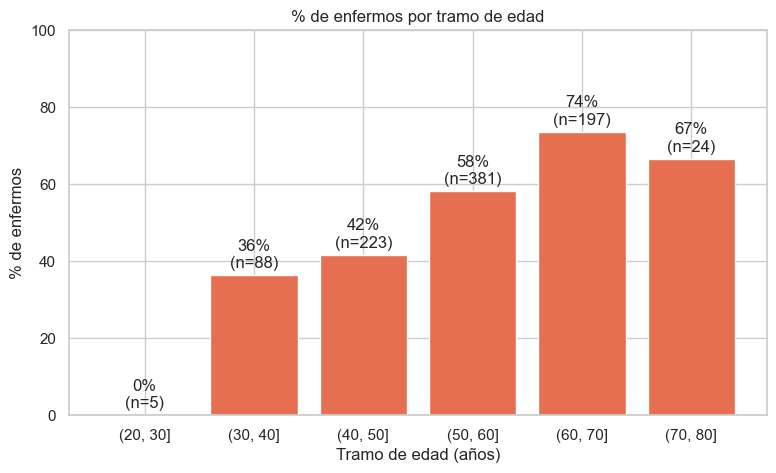

In [33]:
# TODO: pregunta 1
tramos = pd.cut(heart['Age'], bins=[20, 30, 40, 50, 60, 70, 80])
tasa_edad = heart.groupby(tramos, observed=True)['HeartDisease'].agg(['count', 'mean'])
tasa_edad['mean'] = tasa_edad['mean'] * 100
display(tasa_edad.round(1))

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(tasa_edad.index.astype(str), tasa_edad['mean'], color='#e76f51')
ax.bar_label(ax.containers[0], labels=[f'{p:.0f}%\n(n={n})' for p, n in zip(tasa_edad['mean'], tasa_edad['count'])], padding=3)
ax.set_title('% de enfermos por tramo de edad')
ax.set_xlabel('Tramo de edad (años)')
ax.set_ylabel('% de enfermos')
ax.set_ylim(0, 100)
plt.show()

*Interpretación:*

El riesgo empieza a aumentar claramente a partir de los 50 años. Pasa de un 41,7% en el tramo de 40 a 50 a un 58,3% en el de 50 a 60, y sigue subiendo hasta un 73,6% entre los 60 y los 70. En el último tramo (70 a 80) baja a un 66,7%, pero solo hay 24 pacientes y no es fiable

**Pregunta 2.** La angina de esfuerzo (`ExerciseAngina`) y la pendiente ST (`ST_Slope`) salen de la misma prueba. ¿Aportan información distinta o dicen lo mismo? Dibuja un mapa de calor con el **porcentaje de enfermos** en cada combinación de las dos variables, y escribe en cada celda también el número de pacientes.

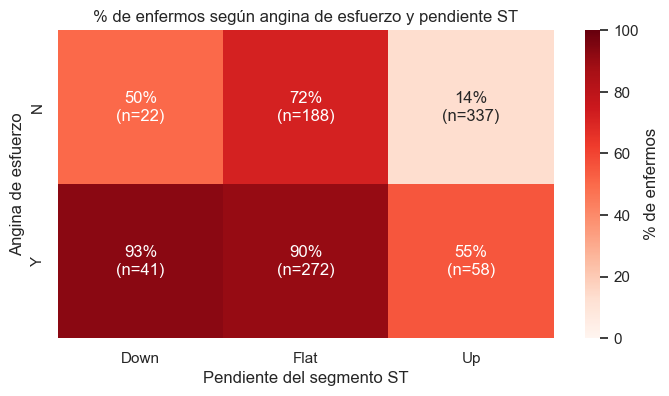

In [34]:
# TODO: pregunta 2
cruce = heart.groupby(['ExerciseAngina', 'ST_Slope'], observed=True)['HeartDisease'].agg(['count', 'mean']).reset_index()
pct_tabla = cruce.pivot(index='ExerciseAngina', columns='ST_Slope', values='mean') * 100
n_tabla = cruce.pivot(index='ExerciseAngina', columns='ST_Slope', values='count')
etiquetas = pct_tabla.round(0).astype(int).astype(str) + '%\n(n=' + n_tabla.astype(int).astype(str) + ')'

plt.figure(figsize=(8, 4))
sns.heatmap(pct_tabla, annot=etiquetas, fmt='', cmap='Reds', vmin=0, vmax=100, cbar_kws={'label': '% de enfermos'})
plt.title('% de enfermos según angina de esfuerzo y pendiente ST')
plt.xlabel('Pendiente del segmento ST')
plt.ylabel('Angina de esfuerzo')
plt.show()

*Interpretación:*

Aportan información distinta. Con la pendiente Up, la angina cambia mucho el resultado: un 13,6% de enfermos sin angina frente a un 55,2% con angina. Con angina y pendiente Down o Flat, más del 90% está enfermo. Sin angina, la pendiente es la que separa: un 13,6% con Up frente a un 71,8% con Flat. Cada variable aporta algo que no dice la otra.

**Pregunta 3.** ¿Tener la glucosa en ayunas alta (`FastingBS = 1`) aumenta el riesgo igual en hombres que en mujeres?

,Sex,FastingBS,count,mean
0,F,False,167,20.4
1,F,True,26,61.5
2,M,False,537,56.6
3,M,True,188,81.9


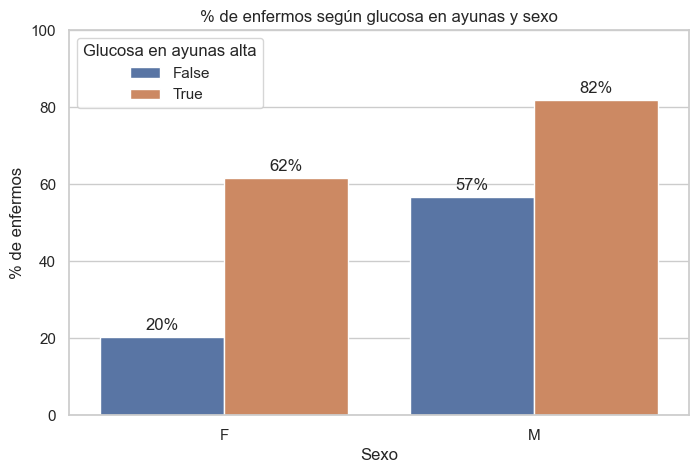

In [35]:
# TODO: pregunta 3
glucosa = heart.groupby(['Sex', 'FastingBS'], observed=True)['HeartDisease'].agg(['count', 'mean']).reset_index()
glucosa['mean'] = glucosa['mean'] * 100
display(glucosa.round(1))

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=glucosa, x='Sex', y='mean', hue='FastingBS')
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt='%.0f%%', padding=3)
plt.title('% de enfermos según glucosa en ayunas y sexo')
plt.xlabel('Sexo')
plt.ylabel('% de enfermos')
plt.ylim(0, 100)
plt.legend(title='Glucosa en ayunas alta')
plt.show()

*Interpretación:*

No aumenta igual. En las mujeres sube 41 puntos (de un 20,4% a un 61,5%) y en los hombres 25 puntos (de un 56,6% a un 81,9%). Aun así, solo hay 26 mujeres con la glucosa alta, así que el dato de las mujeres es poco fiable.

**Parte B — Ficha de síntesis del dataset.**
Completa la ficha con lo que has aprendido en todo el cuaderno. Es el resumen que le darías a otra persona antes de que empiece a limpiar los datos y a entrenar un modelo.

| Apartado | Contenido |
|---|---|
| **Dataset y origen** | |
| **Entidad (qué es cada fila)** | |
| **Volumetría (filas × columnas)** | |
| **Variable objetivo y equilibrio de clases** | |
| **Variables numéricas** | |
| **Variables categóricas (nominales / ordinales / binarias)** | |
| **Cobertura: ¿a quién representa y a quién no?** | |

**Problemas de calidad que hay que tratar en el Bloque 3:**

| Variable | Problema | Nº de filas afectadas | Qué propondrías hacer |
|---|---|---|---|
| | | | |
| | | | |
| | | | |

**Selección de atributos.** Las **5 variables** que crees más útiles para predecir `HeartDisease`, de más a menos, con la evidencia (ejercicio y cifra) que lo justifica:

| # | Variable | Evidencia |
|---|---|---|
| 1 | | |
| 2 | | |
| 3 | | |
| 4 | | |
| 5 | | |

¿Hay alguna variable que **no** usarías, o que usarías con precaución? ¿Por qué?

*Escribe aquí tus respuestas:*

**Ficha del dataset**

| Apartado | Contenido |
|---|---|
| **Dataset y origen** | Heart Failure Prediction (Kaggle, fedesoriano, 2021). Junta cinco conjuntos de UCI de hospitales distintos (Cleveland, Hungría, Suiza, Long Beach y Statlog) y se quitaron los duplicados. |
| **Entidad (qué es cada fila)** | Un paciente estudiado por sospecha de enfermedad cardiaca. No hay identificador del paciente. |
| **Volumetría (filas × columnas)** | 918 filas × 12 columnas, sin duplicados ni nulos reales. |
| **Variable objetivo y equilibrio de clases** | HeartDisease: 508 enfermos (55,34%) y 410 sanos (44,66%). Está bastante equilibrada y un modelo que dijera siempre enfermo acertaría el 55,3%. |
| **Variables numéricas** | Age (28 a 77, media 53,5), RestingBP (media 132,4), Cholesterol (media 198,8, y 244,6 sin ceros), MaxHR (60 a 202, media 136,8) y Oldpeak (-2,6 a 6,2, asimétrica a la derecha). |
| **Variables categóricas (nominales / ordinales / binarias)** | Nominales: ChestPainType y RestingECG. Ordinal: ST_Slope. Binarias: Sex, FastingBS, ExerciseAngina y HeartDisease. |
| **Cobertura: ¿a quién representa y a quién no?** | Pacientes de 28 a 77 años estudiados por sospecha en cinco hospitales. Solo un 21% son mujeres, así que representa mal a las mujeres y a la población general sana. |

**Problemas de calidad que hay que tratar en el Bloque 3**

| Variable | Problema | Nº de filas afectadas | Qué propondrías hacer |
|---|---|---|---|
| Cholesterol | Ceros que en realidad son valores ausentes | 172 (18,74%) | Pasarlos a NaN y rellenarlos (por ejemplo con la mediana) o no usar la variable |
| RestingBP | Un 0 imposible | 1 | Pasarlo a NaN y rellenarlo o eliminar esa fila |
| Oldpeak | Valores negativos y atípicos altos | 13 negativos y 16 atípicos | No son errores, los conservaría |

**Selección de atributos**

| # | Variable | Evidencia |
|---|---|---|
| 1 | ChestPainType | Es la que más diferencia tiene en la tasa de enfermos: 65,1 puntos entre ASY (79%) y ATA (13,9%) (ejercicio 2.3) |
| 2 | ST_Slope | 63,1 puntos de diferencia entre Flat (82,8%) y Up (19,7%) (ejercicio 2.3) |
| 3 | ExerciseAngina | 85,2% de enfermos con angina frente a 35,1% sin ella (ejercicio 2.3) |
| 4 | Oldpeak | Es la que más correlación tiene con la enfermedad: 0,40 con todos los datos y 0,50 sin los ceros (ejercicios 2.4 y 2.5) |
| 5 | MaxHR | Correlación de -0,40 con la enfermedad (ejercicio 2.4) |

Usaría con precaución Cholesterol, porque tiene un 18,74% de ausentes y la paradoja del colesterol (solo sirve después de tratar los ceros). RestingECG apenas separa (14,1 puntos) y RestingBP casi no se relaciona con la enfermedad (0,11), así que aportan poco. Con Sex tendría cuidado por la poca representación de mujeres